# Monitor de Incendios Perú · Retos A y C
**Tarea Clase 5 · Lory Acosta**

Réplica del *Monitor de Incendios Perú* de la clase, ampliado con construcciones (Open Buildings),
población (Censo 2025), agro, bosques y el escenario de lluvias de CENEPRED. Responde dos retos:

- **Reto A · Otro incendio:** medir el **área quemada con dNBR** (Sentinel-2) en incendios activos
  (Río Tambo, Chichas, Manantay y los de mayor prioridad).
- **Reto C · ¿Qué se quemó?:** cruzar esa área quemada con **ESA WorldCover**: bosque, pastizal o cultivo.

Incluye una **vista 3D** del incendio sobre el relieve y una sección de **metodología**.

El resultado es un **dashboard interactivo** (un solo HTML) con filtros por **región y distrito** y mapa.

| Paso | Qué hacemos |
|---|---|
| 1–3 | Focos VIIRS (FIRMS) → incendios (≤ 1 km y ≤ 48 h) → huella y prioridad |
| 4 | Construcciones expuestas (Open Buildings) |
| 4b | Población (WorldPop ajustado al Censo 2025) y agro (WorldCover) |
| 4c | Bosques (Hansen GFC) |
| 4d | **Deforestación oficial**: Geobosques (MINAM-PNCBMCC) y capa SERFOR opcional |
| **5** | **Reto A: área quemada dNBR con Sentinel-2** |
| **6** | **Reto C: área quemada × WorldCover** |
| 7 | Lluvias 22–24 oct (CENEPRED) sobre suelo quemado: riesgo de huaycos |
| 8 | Dashboard interactivo |

### Cómo ejecutarlo en Visual Studio Code
1. Abra este notebook en VS Code y elija el kernel **ds-python-up (3.12)** (arriba a la derecha).
2. Revise la celda **1 · Parámetros** (`EE_PROJECT = "incendios-lo"`).
3. Ejecute **Run All**. La celda **Earth Engine** comprueba la conexión antes de empezar:
   - si falta autorización, abre la página en **Google Chrome**: *CHOOSE PROJECT* → `incendios-lo` →
     *Use read-only scopes* → *GENERATE TOKEN* → copie el código y péguelo en la **caja de texto de
     arriba en VS Code** → Enter;
   - si el proyecto no está registrado o la API está desactivada, abre en Chrome la página exacta para
     arreglarlo y espera a que pulse Enter en la caja de arriba.
4. Al terminar se abre el dashboard `monitor_incendios_retos.html` en Chrome.

## 0 · Preparación
```bash
uv sync --group raster --group geo
uv add earthengine-api folium requests scipy
```
- **Earth Engine (una vez):** registra un proyecto gratis (uso no comercial) en
  https://code.earthengine.google.com/register y pega su ID en `EE_PROJECT`.
- **FIRMS:** sin clave se usan los **últimos 7 días** (como el tablero). Con clave gratuita
  (https://firms.modaps.eosdis.nasa.gov/api/map_key/) puedes elegir otra fecha.

In [1]:
import base64, io, warnings
from datetime import date, timedelta

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from huggingface_hub import hf_hub_download
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.1f}")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

## 1 · Parámetros

In [2]:
EE_PROJECT = "incendios-lo"            # <- ID de tu proyecto de Earth Engine
FIRMS_KEY  = ""                         # vacío = últimos 7 días sin clave
FECHA_FIN  = "2024-09-20"               # solo con FIRMS_KEY
DIAS       = 7                          # solo con FIRMS_KEY

DIST_VECINOS_M = 1000    # focos a <= 1 km ...
HORAS_VECINOS  = 48      # ... y <= 48 h pertenecen al mismo incendio
MIN_FOCOS      = 3       # un incendio necesita >= 3 focos
PIXEL_M        = 375     # lado del píxel VIIRS

RADIO_ALTO_M  = 500      # construcción a <= 500 m del incendio -> exposición alta
RADIO_MEDIO_M = 1000     # entre 500 m y 1 km                    -> exposición media
CONF_MIN      = 0.75     # confianza mínima de Open Buildings (0.65–1.0)
TOP_EE        = 25       # incendios prioritarios a los que se cuentan construcciones
TOP_MAPA      = 3        # incendios cuyas construcciones se dibujan en el mapa
MAX_EDIF_MAPA = 1500     # polígonos por incendio en el mapa

RADIO_POB_M   = 5000     # población a <= 5 km (igual que el tablero de clase)
POB_CENSO_2025 = 34_157_732   # INEI, Censos Nacionales 2025 (primeros resultados, 29/05/2026)
CENSO_DISTRITAL_CSV = None    # opcional: CSV con columnas UBIGEO, POBLACION (Censo 2025 por distrito)
CENAGRO_CSV = None            # opcional: CSV IV CENAGRO 2012 por distrito (UBIGEO, PRODUCTORES, SUP_AGRICOLA_HA)

COBERTURA_BOSQUE = 30   # % de copa para considerar "bosque" (Hansen; MINAM usa ~30 %)
ANIOS_RECIENTE   = 5    # deforestación "reciente" = perdida en los últimos 5 años del dataset

RETOS_NOMBRES = ["RIO TAMBO", "CHICHAS", "MANANTAY"]   # incendios del Reto A (por distrito)
REGIONES_RETOS = ["PUNO"]  # regiones a seguir: se analizan sus N_POR_REGION incendios más grandes
N_POR_REGION  = 3
N_RETOS       = 11       # total de incendios con dNBR (nombrados + regiones + mayor prioridad)
DIAS_PRE      = 75       # ventana "antes": de 75 a 2 días antes del inicio del incendio
DIAS_POST     = 20       # ventana "después": últimos 20 días hasta el corte
NUBES_CS      = 0.60     # Cloud Score+: píxel limpio si cs_cdf >= 0.60
CORTES_DNBR   = [0.10, 0.27, 0.44, 0.66]   # USGS: baja, moderada baja, moderada alta, alta

SERFOR_CAPA  = None      # opcional: ruta a un shapefile de GEOSERFOR (p. ej. concesiones forestales)
SERFOR_CAMPO = None      # columna con el nombre de cada área (None = se detecta)
RADIO_ALERTAS_M = 5000   # alertas de deforestación a <= 5 km de cada incendio prioritario

CRS_METROS = 24891       # CRS métrico de la clase para el Perú
BBOX_PERU  = (-81.4, -18.4, -68.6, 0.1)

## Earth Engine: comprobar conexión y autorizar con Google Chrome
Esta celda se ejecuta **antes** de cualquier cálculo. Diagnostica el error y abre en Chrome lo que haya que arreglar (autorización, registro del proyecto o activar la API).

In [3]:
import os, re, subprocess, sys, webbrowser

# =============================================================================
# Earth Engine: comprobación y autorización con Google Chrome
# =============================================================================
def buscar_chrome():
    import shutil
    cand = []
    if os.name == "nt":
        for base in (os.environ.get("PROGRAMFILES"), os.environ.get("PROGRAMFILES(X86)"),
                     os.environ.get("LOCALAPPDATA")):
            if base:
                cand.append(os.path.join(base, "Google", "Chrome", "Application", "chrome.exe"))
    elif sys.platform == "darwin":
        cand.append("/Applications/Google Chrome.app/Contents/MacOS/Google Chrome")
    for nombre in ("google-chrome", "google-chrome-stable", "chrome", "chromium"):
        ruta = shutil.which(nombre)
        if ruta:
            cand.append(ruta)
    return next((c for c in cand if c and os.path.exists(c)), None)

RUTA_CHROME = buscar_chrome()
_ya_abiertas = set()
_abrir_original = webbrowser.open

def abrir_en_chrome(url):
    """Abre la URL en Google Chrome (o en el navegador predeterminado si no hay Chrome)."""
    if url in _ya_abiertas:
        return True
    _ya_abiertas.add(url)
    if RUTA_CHROME:
        subprocess.Popen([RUTA_CHROME, url], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        print(f"   → Abierto en Google Chrome: {url[:90]}{'…' if len(url) > 90 else ''}")
    else:
        print("   (No encontré Google Chrome; uso el navegador predeterminado)")
        _abrir_original(url)
    return True

# cualquier librería que llame a webbrowser.open() también terminará en Chrome
webbrowser.open = webbrowser.open_new = webbrowser.open_new_tab = lambda url, *a, **k: abrir_en_chrome(url)

class _VigilaURL:
    """Envuelve la salida estándar: cuando Earth Engine imprime el enlace de autorización, lo abre en Chrome."""
    PATRON = re.compile(r"https://code\.earthengine\.google\.com/client-auth[^\s\"'<>]+|https://accounts\.google\.com/o/oauth2[^\s\"'<>]+")
    def __init__(self, real):
        self.real, self.buf = real, ""
    def write(self, s):
        self.real.write(s)
        self.buf += s
        if "\n" in s or len(self.buf) > 4000:
            for m in self.PATRON.finditer(self.buf):
                abrir_en_chrome(m.group(0).rstrip(".,)").replace("&amp;", "&"))
            self.buf = self.buf[-500:]
        return len(s)
    def flush(self):
        self.real.flush()
    def __getattr__(self, nombre):
        return getattr(self.real, nombre)

def autorizar_ee():
    import ee
    print("""
   AUTORIZACIÓN DE EARTH ENGINE (una sola vez)
   Antes: cierre las pestañas viejas de autorización y desactive Google Traductor en esa página.
   1. Se abrirá Google Chrome. Elija la cuenta dueña del proyecto y pulse Continuar/Permitir.
      Si ve "The authentication flow has completed", ya está: vuelva a VS Code.
   Solo si se abre la página "Notebook Authenticator":
   2. CHOOSE PROJECT -> elija su proyecto -> marque "Use read-only scopes".
   3. GENERATE TOKEN -> Permitir -> copie el código (ícono de copiar).
   4. Pegue el código donde se lo pidan y pulse Enter:
      en el notebook de VS Code, en la caja de texto de arriba; en la terminal, aquí mismo.
   (Si Chrome no se abre, copie el enlace que aparece abajo y péguelo en Chrome.)
""")
    real = sys.stdout
    sys.stdout = _VigilaURL(real)
    parches = []
    try:                                   # en notebooks el enlace llega por display(HTML): también se vigila
        import IPython.display as _ipd
        _orig = _ipd.display
        def _display_vigilado(*objs, **kw):
            for o in objs:
                texto = getattr(o, "data", None) or (o._repr_html_() if hasattr(o, "_repr_html_") else str(o))
                for m in _VigilaURL.PATRON.finditer(str(texto)):
                    abrir_en_chrome(m.group(0).rstrip(".,)").replace("&amp;", "&"))
            return _orig(*objs, **kw)
        _ipd.display = _display_vigilado
        parches.append((_ipd, "display", _orig))
    except Exception:
        pass
    try:
        try:
            # 1º método "localhost": Chrome inicia sesión y la autorización se guarda sola (sin copiar códigos)
            print("   Método 1: inicio de sesión directo en Chrome (no hay que copiar ningún código)…")
            ee.Authenticate(auth_mode="localhost", force=True)
        except Exception as err:
            print(f"   El método directo no funcionó ({err}). Método 2: código de verificación…")
            ee.Authenticate(auth_mode="notebook", force=True)
    finally:
        sys.stdout = real
        for mod, nombre, orig in parches:
            setattr(mod, nombre, orig)

def preparar_earth_engine(proyecto, forzar_autorizacion=False, intentos=4):
    """Devuelve True si Earth Engine responde. Diagnostica el error y abre en Chrome lo que haya que arreglar."""
    try:
        import ee
    except ImportError:
        print("Falta la librería: ejecute  uv add earthengine-api")
        return False
    if forzar_autorizacion:
        autorizar_ee()
    for intento in range(1, intentos + 1):
        try:
            ee.Initialize(project=proyecto)
            ee.Number(1).getInfo()                     # prueba real contra el servidor
            print(f"✅ Earth Engine conectado (proyecto {proyecto})")
            return True
        except Exception as err:
            msg = str(err)
            bajo = msg.lower()
            print(f"\n⚠ Earth Engine (intento {intento}/{intentos}): {msg}\n")
            if intento == intentos:
                break
            if ("not registered" in bajo or "not signed up" in bajo or "register" in bajo) and "authorize" not in bajo:
                print("   El proyecto no está registrado en Earth Engine. Regístrelo como uso NO comercial,")
                print("   categoría Academia & Research, nivel Community (gratis).")
                abrir_en_chrome(f"https://console.cloud.google.com/earth-engine/configuration?project={proyecto}")
                input("   Cuando termine el registro, pulse Enter para reintentar… ")
            elif any(t in bajo for t in ("has not been used", "is disabled", "service_disabled", "enable it",
                                          "api has not")):
                print("   La API de Earth Engine está desactivada en el proyecto. Pulse HABILITAR (Enable).")
                abrir_en_chrome(f"https://console.cloud.google.com/apis/library/earthengine.googleapis.com?project={proyecto}")
                input("   Cuando la API esté habilitada (espere 1-2 minutos), pulse Enter para reintentar… ")
            elif any(t in bajo for t in ("not found", "does not exist", "invalid project")):
                print(f"   No existe un proyecto con ID '{proyecto}'. Revise el ID exacto en la consola.")
                abrir_en_chrome("https://console.cloud.google.com/projectselector2/home/dashboard")
                nuevo = input("   Escriba el ID correcto del proyecto (o Enter para salir): ").strip()
                if not nuevo:
                    break
                proyecto = nuevo
            elif any(t in bajo for t in ("permission", "caller does not have", "forbidden", "403")):
                print("   La cuenta autorizada no tiene permiso en este proyecto. Autorice con la cuenta dueña.")
                autorizar_ee()
            else:                                       # credenciales ausentes, vencidas o inválidas
                autorizar_ee()
    print("❌ Earth Engine no disponible: el dashboard saldrá solo con datos de FIRMS (sin Retos A y C).")
    return False

EE_LISTO = preparar_earth_engine(EE_PROJECT)
if EE_LISTO:
    import ee



⚠ Earth Engine (intento 1/4): Please authorize access to your Earth Engine account by running

earthengine authenticate

in your command line, or ee.Authenticate() in Python, and then retry.


   AUTORIZACIÓN DE EARTH ENGINE (una sola vez)
   Antes: cierre las pestañas viejas de autorización y desactive Google Traductor en esa página.
   1. Se abrirá Google Chrome. Elija la cuenta dueña del proyecto y pulse Continuar/Permitir.
      Si ve "The authentication flow has completed", ya está: vuelva a VS Code.
   Solo si se abre la página "Notebook Authenticator":
   2. CHOOSE PROJECT -> elija su proyecto -> marque "Use read-only scopes".
   3. GENERATE TOKEN -> Permitir -> copie el código (ícono de copiar).
   4. Pegue el código donde se lo pidan y pulse Enter:
      en el notebook de VS Code, en la caja de texto de arriba; en la terminal, aquí mismo.
   (Si Chrome no se abre, copie el enlace que aparece abajo y péguelo en Chrome.)

   Método 1: inicio de sesión directo en Chrome (no hay 


Successfully saved authorization token.
✅ Earth Engine conectado (proyecto incendios-lo)


## 2 · Focos de calor (NASA FIRMS, tres satélites VIIRS)
Igual que el tablero de clase: S-NPP, NOAA-20 y NOAA-21. Cada fila es un píxel de 375 m
con fuego, con fecha/hora (UTC), confianza y FRP (potencia radiativa, MW).

In [4]:
SAT_7D = {
    "S-NPP":   "suomi-npp-viirs-c2/csv/SUOMI_VIIRS_C2_South_America_7d.csv",
    "NOAA-20": "noaa-20-viirs-c2/csv/J1_VIIRS_C2_South_America_7d.csv",
    "NOAA-21": "noaa-21-viirs-c2/csv/J2_VIIRS_C2_South_America_7d.csv",
}
SAT_API = {"S-NPP": "VIIRS_SNPP", "NOAA-20": "VIIRS_NOAA20", "NOAA-21": "VIIRS_NOAA21"}

def leer_csv(url):
    return pd.read_csv(url)

def cargar_firms() -> pd.DataFrame:
    w, s, e, n = BBOX_PERU
    partes = []
    for sat in SAT_7D:
        try:
            if not FIRMS_KEY:
                d = leer_csv("https://firms.modaps.eosdis.nasa.gov/data/active_fire/" + SAT_7D[sat])
            else:   # API por tramos de 5 días
                fin, faltan, trozos = date.fromisoformat(FECHA_FIN), DIAS, []
                tipo = "_SP" if (date.today() - fin).days > 90 else "_NRT"
                while faltan > 0:
                    tramo = min(5, faltan)
                    ini = fin - timedelta(days=faltan - 1)
                    trozos.append(leer_csv(f"https://firms.modaps.eosdis.nasa.gov/api/area/csv/"
                        f"{FIRMS_KEY}/{SAT_API[sat]}{tipo}/{w},{s},{e},{n}/{tramo}/{ini}"))
                    faltan -= tramo
                d = pd.concat(trozos, ignore_index=True)
            d["satelite"] = sat
            partes.append(d)
            print(f"{sat:8s}: {len(d):,} focos")
        except Exception as err:
            print(f"{sat:8s}: no disponible ({err.__class__.__name__})")
    return pd.concat(partes, ignore_index=True)

crudo = cargar_firms()

S-NPP   : 50,903 focos
NOAA-20 : 52,142 focos
NOAA-21 : 49,581 focos


In [5]:
df = crudo.copy()
w, s, e, n = BBOX_PERU
df = df[df.latitude.between(s, n) & df.longitude.between(w, e)]
df = df[df["confidence"].astype(str).str.lower().str[0] != "l"]   # fuera confianza baja
if "type" in df:
    df = df[df["type"] == 0]                                       # solo vegetación

# fecha-hora: FIRMS viene en UTC (acq_time = HHMM) -> hora de Lima
hhmm = df["acq_time"].astype(int).astype(str).str.zfill(4)
df["t"] = (pd.to_datetime(df["acq_date"] + " " + hhmm, format="%Y-%m-%d %H%M")
           - pd.Timedelta(hours=5))

focos = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                         crs="EPSG:4326")

# solo focos dentro de distritos peruanos (el recuadro incluye Brasil y Bolivia)
REPO = "aquiro1994/ds-python-up"
def traer(ruta): return hf_hub_download(REPO, ruta, repo_type="dataset")
def traer_shapefile(base):
    p = traer(f"{base}.shp")
    for ext in ("dbf", "shx", "prj", "cpg"):
        try: traer(f"{base}.{ext}")
        except Exception: pass
    return p

distritos = gpd.read_file(traer_shapefile("_data/Folium/DISTRITOS")).to_crs("EPSG:4326")
focos = (gpd.sjoin(focos, distritos[["DEPARTAMEN", "PROVINCIA", "DISTRITO", "geometry"]],
                   how="inner", predicate="within")
         .drop(columns="index_right").reset_index(drop=True))

CORTE = focos["t"].max()
focos["edad_h"] = (CORTE - focos["t"]).dt.total_seconds() / 3600
focos["ventana"] = np.where(focos.edad_h <= 24, "24 h", "1 a 7 días")
print(f"corte: {CORTE:%d %b %Y, %H:%M} h (Lima)")
print(f"focos en el Perú: {len(focos):,}  |  últimas 24 h: {(focos.edad_h <= 24).sum():,}")

corte: 21 Oct 2026, 14:19 h (Lima)
focos en el Perú: 7,145  |  últimas 24 h: 343


## 3 · De focos a incendios
Dos focos son **vecinos** si están a ≤ 1 km y ≤ 48 h. Un incendio es un *componente
conexo* de esa red de vecinos: si A es vecino de B y B de C, A, B y C son el mismo incendio.
`cKDTree` encuentra los pares cercanos en metros (por eso proyectamos a EPSG:24891).

In [6]:
focos_m = focos.to_crs(epsg=CRS_METROS)
xy = np.c_[focos_m.geometry.x, focos_m.geometry.y]

pares = cKDTree(xy).query_pairs(DIST_VECINOS_M, output_type="ndarray")
horas = np.abs((focos["t"].values[pares[:, 0]] - focos["t"].values[pares[:, 1]])
               / np.timedelta64(1, "h"))
pares = pares[horas <= HORAS_VECINOS]

grafo = coo_matrix((np.ones(len(pares)), (pares[:, 0], pares[:, 1])), shape=(len(focos),) * 2)
_, etiqueta = connected_components(grafo, directed=False)
focos["incendio"] = focos_m["incendio"] = etiqueta
print(f"{focos.incendio.nunique():,} grupos de focos")

2,233 grupos de focos


**Huella:** cada foco es un cuadrado de 375 × 375 m (≈ 14 ha). La huella del incendio es
la unión de esos cuadrados, así los píxeles repetidos por dos satélites no se cuentan dos veces.

In [7]:
cuadros = focos_m.copy()
cuadros["geometry"] = focos_m.buffer(PIXEL_M / 2, cap_style=3)          # 3 = cuadrado
cuadros_24 = cuadros[cuadros.edad_h <= 24]

huella = cuadros.dissolve("incendio").geometry
huella_previa = cuadros[cuadros.edad_h > 24].dissolve("incendio").geometry

def moda(x): return x.value_counts().index[0]

inc = focos.groupby("incendio").agg(
    focos=("t", "size"),
    focos_24h=("edad_h", lambda x: (x <= 24).sum()),
    inicio=("t", "min"), ultimo=("t", "max"),
    frp_total=("frp", "sum"),
    DISTRITO=("DISTRITO", moda), PROVINCIA=("PROVINCIA", moda), DEPARTAMEN=("DEPARTAMEN", moda),
    lat=("latitude", "mean"), lon=("longitude", "mean"),
)
inc["huella_ha"] = huella.area.reindex(inc.index) / 1e4
inc["huella_nueva_ha"] = (inc["huella_ha"]
                          - (huella_previa.area.reindex(inc.index).fillna(0) / 1e4)).clip(lower=0)
inc["dias"] = (inc.ultimo - inc.inicio).dt.total_seconds() / 86400

activos = inc[(inc.focos >= MIN_FOCOS) & (inc.focos_24h > 0)].copy()
print(f"incendios activos: {len(activos):,}  |  > 100 ha: {(activos.huella_ha > 100).sum():,}")

incendios activos: 47  |  > 100 ha: 10


**Índice de prioridad (0–100).** Percentil del incendio en tres dimensiones:
tamaño (huella, 40 %), actividad (focos en 24 h, 30 %) e intensidad (FRP, 30 %).
Después de contar construcciones se suma esa dimensión (ver sección 4).

In [8]:
pct = lambda s: s.rank(pct=True)
activos["prioridad_base"] = (100 * (0.4 * pct(activos.huella_ha)
                                    + 0.3 * pct(activos.focos_24h)
                                    + 0.3 * pct(activos.frp_total))).round()
activos = activos.sort_values("prioridad_base", ascending=False)
activos.head(10)[["DISTRITO", "DEPARTAMEN", "huella_ha", "huella_nueva_ha",
                  "focos_24h", "dias", "prioridad_base"]]

,DISTRITO,DEPARTAMEN,huella_ha,huella_nueva_ha,focos_24h,dias,prioridad_base
incendio,,,,,,,
1149,MOQUEGUA,MOQUEGUA,216.6,99.7,9,1.0,98.0
1113,LAS PIEDRAS,MADRE DE DIOS,107.9,40.0,8,1.1,92.0
1155,LABERINTO,MADRE DE DIOS,107.9,107.9,10,0.0,91.0
1148,MOQUEGUA,MOQUEGUA,213.9,73.2,7,1.0,89.0
1168,TAHUAMANU,MADRE DE DIOS,112.9,98.8,9,1.0,88.0
55,PARACAS,ICA,106.5,7.1,6,6.6,84.0
1151,LA JOYA,AREQUIPA,132.4,90.2,8,1.0,83.0
1206,MASISEA,UCAYALI,70.3,70.3,7,0.0,77.0
379,TAHUANIA,UCAYALI,121.8,6.8,3,6.1,72.0


## 4 · ➕ Capa nueva: construcciones expuestas (Google Open Buildings v3)
Open Buildings detecta huellas de edificaciones en imágenes satelitales de alta resolución
(columnas: `area_in_meters`, `confidence`, geometría). La descarga directa pesa hasta 7.8 GB
por tile, así que **contamos en el servidor de Earth Engine** y solo bajamos polígonos para
los incendios que se dibujan en el mapa.

Para cada incendio prioritario se cuentan construcciones en dos anillos alrededor de su huella:
**≤ 500 m (exposición alta)** y **≤ 1 km (exposición media)**.

In [9]:
extra = [i for reg in REGIONES_RETOS
         for i in activos[activos.DEPARTAMEN == reg.upper()].nlargest(N_POR_REGION, "huella_ha").index]
top = activos.loc[list(dict.fromkeys(list(activos.head(TOP_EE).index) + extra))].copy()
huella_top = gpd.GeoSeries(huella.reindex(top.index), crs=CRS_METROS)
zona_alta  = huella_top.buffer(RADIO_ALTO_M).to_crs(4326).simplify(0.0003)
zona_media = huella_top.buffer(RADIO_MEDIO_M).to_crs(4326).simplify(0.0003)

EE_OK = False
try:
    if not EE_LISTO:
        raise RuntimeError("Earth Engine no disponible (ver la celda de Earth Engine)")
    OB = (ee.FeatureCollection("GOOGLE/Research/open-buildings/v3/polygons")
            .filter(ee.Filter.gte("confidence", CONF_MIN)))

    def contar(zonas):
        fc = ee.FeatureCollection([ee.Feature(ee.Geometry(g.__geo_interface__), {"id": int(i)})
                                   for i, g in zonas.items()])
        fc = fc.map(lambda f: f.set("n", OB.filterBounds(f.geometry()).size()))
        res = fc.reduceColumns(ee.Reducer.toList(2), ["id", "n"]).get("list").getInfo()
        return pd.Series({int(i): int(v) for i, v in res})

    top["edif_500m"] = contar(zona_alta).reindex(top.index).fillna(0).astype(int)
    top["edif_1km"]  = contar(zona_media).reindex(top.index).fillna(0).astype(int)
    EE_OK = True
except Exception as err:
    print("Earth Engine no disponible:", err)
    top["edif_500m"] = top["edif_1km"] = np.nan

print(f"construcciones a <= 1 km de los {len(top)} incendios prioritarios: "
      f"{top.edif_1km.sum():,.0f}  (a <= 500 m: {top.edif_500m.sum():,.0f})")
top.sort_values("edif_1km", ascending=False).head(10)[
    ["DISTRITO", "DEPARTAMEN", "huella_ha", "edif_500m", "edif_1km"]]

construcciones a <= 1 km de los 26 incendios prioritarios: 2,440  (a <= 500 m: 1,506)


,DISTRITO,DEPARTAMEN,huella_ha,edif_500m,edif_1km
incendio,,,,,
1636,JULI,PUNO,32.9,540,945
55,PARACAS,ICA,106.5,441,543
1149,MOQUEGUA,MOQUEGUA,216.6,156,272
1049,PACOCHA,MOQUEGUA,65.6,111,211
1148,MOQUEGUA,MOQUEGUA,213.9,48,108
1150,MOLLENDO,AREQUIPA,85.3,69,103
1165,LAS PIEDRAS,MADRE DE DIOS,52.9,60,84
1154,TIQUILLACA,PUNO,56.2,25,43
1633,SANTA ROSA,CAJAMARCA,56.2,4,43


Prioridad final: se agrega la exposición de construcciones (25 %) y se reescalan
las demás dimensiones al 75 % restante.

In [10]:
if EE_OK:
    top["prioridad"] = (0.75 * top.prioridad_base
                        + 25 * top.edif_1km.rank(pct=True)).round().astype(int)
else:
    top["prioridad"] = top.prioridad_base.astype(int)
top = top.sort_values("prioridad", ascending=False)

Polígonos para el mapa: construcciones de los `TOP_MAPA` incendios con más edificaciones
expuestas, clasificadas por distancia a la huella del incendio.

In [11]:
edif_mapa = []
if EE_OK:
    for i in top.sort_values("edif_1km", ascending=False).head(TOP_MAPA).index:
        g = ee.Geometry(zona_media[i].__geo_interface__)
        feats = OB.filterBounds(g).limit(MAX_EDIF_MAPA).getInfo()["features"]
        if not feats:
            continue
        b = gpd.GeoDataFrame.from_features(feats, crs=4326).to_crs(CRS_METROS)
        b["dist_m"] = b.distance(huella[i])
        b["exposicion"] = np.where(b.dist_m <= RADIO_ALTO_M, "Alta (≤ 500 m)", "Media (500 m–1 km)")
        b["incendio"] = top.loc[i, "DISTRITO"]
        edif_mapa.append(b.to_crs(4326))
edif_mapa = (pd.concat(edif_mapa, ignore_index=True) if edif_mapa
             else gpd.GeoDataFrame(columns=["exposicion", "dist_m", "area_in_meters", "incendio", "geometry"],
                                   geometry="geometry", crs=4326))
print(f"polígonos para el mapa: {len(edif_mapa):,}")

polígonos para el mapa: 1,760


## 4b · ➕ Población y actividad agropecuaria expuestas
**Población.** El último censo es el de los **Censos Nacionales 2025** (INEI publicó los primeros
resultados el 29/05/2026: **34 157 732 habitantes**). El censo cuenta personas por distrito, pero un
incendio no respeta límites distritales: necesitamos saber *dónde* vive la gente dentro del distrito.
Para eso usamos **WorldPop** (población estimada cada 100 m) y lo **ajustamos al Censo 2025**:

- Sin datos distritales: todo WorldPop se escala para que el Perú sume el total del Censo 2025.
- Con `CENSO_DISTRITAL_CSV`: cada distrito se escala a su población censal (más preciso).

**Agro.** El último censo agropecuario es el **IV CENAGRO 2012** (no hubo uno posterior; la ENA
es una encuesta y no baja a distrito). Para medir qué hay *hoy* alrededor del fuego usamos
**ESA WorldCover** (10 m): hectáreas de **cultivos**, **pastos** y **bosque** dentro de la huella
y a ≤ 1 km. El CENAGRO, si lo cargas, da contexto: cuántos productores tiene el distrito.

In [12]:

AGRO_OK = False
if EE_OK:
    WP = (ee.ImageCollection("WorldPop/GP/100m/pop")
            .filter(ee.Filter.eq("country", "PER")).filter(ee.Filter.eq("year", 2020))
            .first().select("population"))

    # factor nacional: total Censo 2025 / total WorldPop 2020
    peru = ee.Geometry.Rectangle(list(BBOX_PERU))
    wp_total = WP.reduceRegion(ee.Reducer.sum(), peru, 100, maxPixels=1e10,
                               tileScale=4).get("population").getInfo()
    factor_nac = POB_CENSO_2025 / wp_total
    print(f"WorldPop 2020 Perú: {wp_total:,.0f}  ->  factor al Censo 2025: {factor_nac:.3f}")

    def sumar(imagen, zonas, escala):
        """Suma de cada banda de la imagen dentro de cada zona (GeoSeries en 4326)."""
        fc = ee.FeatureCollection([ee.Feature(ee.Geometry(g.__geo_interface__), {"id": int(i)})
                                   for i, g in zonas.items()])
        res = imagen.reduceRegions(fc, ee.Reducer.sum(), escala, tileScale=4).getInfo()
        filas = {f["properties"].pop("id"): f["properties"] for f in res["features"]}
        return pd.DataFrame.from_dict(filas, orient="index")

    zona_pob = huella_top.buffer(RADIO_POB_M).to_crs(4326).simplify(0.001)
    pob5 = sumar(WP, zona_pob, 100)["sum"]
    pob1 = sumar(WP, zona_media, 100)["sum"]

    # ajuste distrital opcional con el Censo 2025
    factor = pd.Series(factor_nac, index=top.index)
    if CENSO_DISTRITAL_CSV:
        censo = pd.read_csv(CENSO_DISTRITAL_CSV, dtype={"UBIGEO": str})
        col_ub = next(c for c in distritos.columns if c.upper() in ("UBIGEO", "IDDIST", "CODDIST"))
        d_top = distritos[distritos.DISTRITO.isin(top.DISTRITO)].drop_duplicates("DISTRITO")
        wp_dist = sumar(WP, d_top.set_index(d_top.index).geometry.simplify(0.001), 100)["sum"]
        d_top = d_top.assign(wp=wp_dist.values).merge(censo, left_on=col_ub, right_on="UBIGEO")
        f_dist = (d_top.POBLACION / d_top.wp).set_axis(d_top.DISTRITO)
        factor = top.DISTRITO.map(f_dist).fillna(factor_nac)
        print("ajuste distrital con el Censo 2025 aplicado")

    top["pob_5km"] = (pob5.reindex(top.index) * factor).round()
    top["pob_1km"] = (pob1.reindex(top.index) * factor).round()

    # cobertura del suelo (ESA WorldCover 2021): 10 bosque, 30 pastos, 40 cultivos
    WC = ee.ImageCollection("ESA/WorldCover/v200").first()
    ha = ee.Image.pixelArea().divide(1e4)
    cob = (ha.updateMask(WC.eq(40)).rename("cultivos")
           .addBands(ha.updateMask(WC.eq(30)).rename("pastos"))
           .addBands(ha.updateMask(WC.eq(10)).rename("bosque")))
    zona_huella = huella_top.to_crs(4326).simplify(0.0003)
    en_huella = sumar(cob, zona_huella, 20).reindex(top.index)
    a_1km = sumar(cob, zona_media, 20).reindex(top.index)
    for c in ("cultivos", "pastos", "bosque"):
        top[f"{c}_huella_ha"] = en_huella.get(c, 0).fillna(0).round()
        top[f"{c}_1km_ha"] = a_1km.get(c, 0).fillna(0).round()
    AGRO_OK = True
else:
    for c in ("pob_5km", "pob_1km", "cultivos_huella_ha", "cultivos_1km_ha", "pastos_huella_ha",
              "pastos_1km_ha", "bosque_huella_ha", "bosque_1km_ha"):
        top[c] = np.nan

# contexto CENAGRO 2012 (opcional)
if CENAGRO_CSV:
    agro = pd.read_csv(CENAGRO_CSV, dtype={"UBIGEO": str})
    col_ub = next(c for c in distritos.columns if c.upper() in ("UBIGEO", "IDDIST", "CODDIST"))
    ub = distritos.drop_duplicates("DISTRITO").set_index("DISTRITO")[col_ub]
    top = top.join(agro.set_index("UBIGEO")[["PRODUCTORES", "SUP_AGRICOLA_HA"]],
                   on=top.DISTRITO.map(ub))

print(f"personas a <= 5 km: {top.pob_5km.sum():,.0f}  |  a <= 1 km: {top.pob_1km.sum():,.0f}")
print(f"cultivos a <= 1 km: {top.cultivos_1km_ha.sum():,.0f} ha  |  pastos: {top.pastos_1km_ha.sum():,.0f} ha")
top.sort_values("pob_5km", ascending=False).head(10)[
    ["DISTRITO", "DEPARTAMEN", "pob_1km", "pob_5km", "cultivos_1km_ha", "pastos_1km_ha"]]


WorldPop 2020 Perú: 30,853,475  ->  factor al Censo 2025: 1.107
personas a <= 5 km: 26,024  |  a <= 1 km: 4,672
cultivos a <= 1 km: 333 ha  |  pastos: 2,743 ha


,DISTRITO,DEPARTAMEN,pob_1km,pob_5km,cultivos_1km_ha,pastos_1km_ha
incendio,,,,,,
55,PARACAS,ICA,"2,278.0","5,668.0",33.0,6.0
1636,JULI,PUNO,530.0,"4,421.0",285.0,334.0
1633,SANTA ROSA,CAJAMARCA,233.0,"3,722.0",0.0,155.0
1148,MOQUEGUA,MOQUEGUA,131.0,"2,048.0",0.0,0.0
1049,PACOCHA,MOQUEGUA,940.0,"1,624.0",0.0,0.0
1195,PUERTO BERMUDEZ,PASCO,66.0,"1,490.0",0.0,36.0
1151,LA JOYA,AREQUIPA,35.0,"1,222.0",0.0,0.0
1150,MOLLENDO,AREQUIPA,55.0,"1,181.0",0.0,1.0
1084,SANTO DOMINGO DE ACOBAMBA,JUNIN,102.0,"1,091.0",0.0,582.0


## 4c · ➕ Bosques y deforestación
**Fuente:** *Global Forest Change* (Hansen et al., Universidad de Maryland), en Earth Engine. Para cada
píxel de 30 m dice si había bosque en 2000 (% de copa) y **en qué año se perdió**. Es la misma familia
de datos que usa Geobosques (MINAM) para reportar la pérdida de bosque en el Perú.

Con eso clasificamos **cada foco de calor** según dónde cae:

| Clase | Qué significa | Lectura para decidir |
|---|---|---|
| **Bosque en pie** | había bosque y no se ha perdido | incendio forestal: proteger el bosque |
| **Deforestación reciente** | el bosque se perdió en los últimos 5 años | probable **quema para deforestar o limpiar el terreno**: fiscalizar |
| **Deforestación antigua** | se perdió hace más de 5 años | quema en tierra ya convertida (chacra, pasto) |
| **Sin bosque** | no había bosque en 2000 | puna, pastos, costa, cultivos |

> Limitación: Hansen detecta pérdida de copa por cualquier causa (tala, fuego, río). La lectura
> «quema para deforestar» es una hipótesis razonable, no una prueba.

In [13]:

BOSQUE_OK = False
CLASES = {1: "Bosque en pie", 2: "Deforestación reciente", 3: "Deforestación antigua", 0: "Sin bosque"}
if EE_OK:
    for gid in ["UMD/hansen/global_forest_change_2025_v1_13",
                "UMD/hansen/global_forest_change_2024_v1_12",
                "UMD/hansen/global_forest_change_2023_v1_11"]:
        try:
            gfc = ee.Image(gid); gfc.bandNames().getInfo()
            GFC_ID, ULTIMO = gid, int(gid.split("_")[-3]); break
        except Exception:
            continue
    print(f"dataset: {GFC_ID}  (pérdida hasta {ULTIMO})")

    era_bosque = gfc.select("treecover2000").gte(COBERTURA_BOSQUE)
    perdida = gfc.select("lossyear")                    # 0 = sin pérdida; 1..24 = 2001..2024
    reciente = perdida.gt(ULTIMO - 2000 - ANIOS_RECIENTE)
    clase = (ee.Image(0)
             .where(era_bosque.And(perdida.eq(0)), 1)
             .where(era_bosque.And(reciente), 2)
             .where(era_bosque.And(perdida.gt(0)).And(reciente.Not()), 3)
             .rename("clase"))

    # (a) clase de cada foco de calor del Perú (por tramos de 2 000 puntos)
    valores = []
    for ini in range(0, len(focos), 2000):
        sub = focos.iloc[ini:ini + 2000]
        fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([x, y]), {"k": int(k)})
                                   for k, x, y in zip(sub.index, sub.longitude, sub.latitude)])
        res = clase.sampleRegions(fc, scale=30, geometries=False).getInfo()["features"]
        valores += [(f["properties"]["k"], f["properties"]["clase"]) for f in res]
    focos["bosque"] = pd.Series(dict(valores)).reindex(focos.index).fillna(0).astype(int).map(CLASES)
    print(focos.bosque.value_counts(normalize=True).mul(100).round(1).to_string())

    # (b) hectáreas por clase dentro de la huella y a <= 1 km de cada incendio prioritario
    ha = ee.Image.pixelArea().divide(1e4)
    capas = (ha.updateMask(clase.eq(1)).rename("bosque_pie")
             .addBands(ha.updateMask(clase.eq(2)).rename("defor_reciente")))
    en_h = sumar(capas, zona_huella, 30).reindex(top.index)
    a_1k = sumar(capas, zona_media, 30).reindex(top.index)
    top["bosque_pie_huella_ha"] = en_h.get("bosque_pie", 0).fillna(0).round()
    top["defor_reciente_1km_ha"] = a_1k.get("defor_reciente", 0).fillna(0).round()

    # (c) tipo de incendio según dónde cayeron sus focos
    mezcla = pd.crosstab(focos.incendio, focos.bosque, normalize="index")
    def tipo(i):
        if i not in mezcla.index: return "Sin dato"
        m = mezcla.loc[i]
        if m.get("Deforestación reciente", 0) >= 0.4: return "Probable quema para deforestar"
        if m.get("Bosque en pie", 0) >= 0.4: return "Incendio en bosque"
        return "Quema en zona sin bosque / agropecuaria"
    top["tipo"] = [tipo(i) for i in top.index]

    # (d) pérdida de bosque por año alrededor de los incendios prioritarios (contexto histórico)
    zonas_union = ee.Geometry(zona_media.unary_union.__geo_interface__)
    hist = (ha.addBands(perdida).updateMask(era_bosque.And(perdida.gt(0)))
              .reduceRegion(ee.Reducer.sum().group(groupField=1, groupName="anio"),
                            zonas_union, 30, maxPixels=1e10, tileScale=4)
              .get("groups").getInfo())
    perdida_anual = pd.Series({2000 + int(g["anio"]): g["sum"] for g in hist}).sort_index()

    # capa para el mapa: pérdida de bosque coloreada por año
    vis = perdida.updateMask(perdida.gt(0)).visualize(min=1, max=ULTIMO - 2000,
                                                    palette=["#ffffb2", "#fd8d3c", "#bd0026"])
    URL_PERDIDA = vis.getMapId()["tile_fetcher"].url_format
    BOSQUE_OK = True
else:
    focos["bosque"] = "Sin dato"
    top["bosque_pie_huella_ha"] = top["defor_reciente_1km_ha"] = np.nan
    top["tipo"] = "Sin dato"
    perdida_anual, URL_PERDIDA = pd.Series(dtype=float), None

top[["DISTRITO", "DEPARTAMEN", "huella_ha", "bosque_pie_huella_ha",
     "defor_reciente_1km_ha", "tipo"]].head(10)


dataset: UMD/hansen/global_forest_change_2025_v1_13  (pérdida hasta 2025)
bosque
Sin bosque               74.1
Deforestación antigua    14.0
Deforestación reciente   11.9


,DISTRITO,DEPARTAMEN,huella_ha,bosque_pie_huella_ha,defor_reciente_1km_ha,tipo
incendio,,,,,,
1149,MOQUEGUA,MOQUEGUA,216.6,0,0.0,Quema en zona sin bosque / agropecuaria
1148,MOQUEGUA,MOQUEGUA,213.9,0,0.0,Quema en zona sin bosque / agropecuaria
55,PARACAS,ICA,106.5,0,0.0,Quema en zona sin bosque / agropecuaria
1113,LAS PIEDRAS,MADRE DE DIOS,107.9,0,47.0,Quema en zona sin bosque / agropecuaria
1168,TAHUAMANU,MADRE DE DIOS,112.9,0,96.0,Quema en zona sin bosque / agropecuaria
1155,LABERINTO,MADRE DE DIOS,107.9,0,113.0,Quema en zona sin bosque / agropecuaria
1165,LAS PIEDRAS,MADRE DE DIOS,52.9,0,41.0,Quema en zona sin bosque / agropecuaria
1195,PUERTO BERMUDEZ,PASCO,55.7,0,42.0,Quema en zona sin bosque / agropecuaria
1150,MOLLENDO,AREQUIPA,85.3,0,0.0,Quema en zona sin bosque / agropecuaria


## 4d · ➕ Deforestación oficial: Geobosques (MINAM) y SERFOR
El **Programa Nacional de Conservación de Bosques para la Mitigación del Cambio Climático** (PNCBMCC, MINAM)
publica en **Geobosques** el mapa oficial de **bosque / no bosque** y la **pérdida de bosque húmedo amazónico**
por año. Usamos su **API pública** (sin clave):

| Servicio | Qué devuelve |
|---|---|
| `BOSQUEPERDIDA/stockBosquePerdidaDistrito` | bosque que queda (ha, último año) y pérdida anual 2001–último año, por **ubigeo** de distrito |
| `ALERTAS/ultimasByCobertura` | puntos de **alertas tempranas de deforestación** de la última semana dentro de un polígono |

Las respuestas se guardan en `geobosques_cache.json` para no repetir consultas.

**SERFOR (opcional).** Si descargas de GEOSERFOR una capa forestal en shapefile (por ejemplo, concesiones
forestales o bosques de producción permanente) y pones su ruta en `SERFOR_CAPA`, se cuentan los focos dentro
de cada área.

> Geobosques cubre el **bosque húmedo amazónico**. Los incendios de puna (por ejemplo, en Puno) o costa no
> tendrán cifras aquí; para ellos sirven el Reto C (WorldCover) y la clase Hansen de cada foco.

In [14]:
import json, os, requests
from concurrent.futures import ThreadPoolExecutor

GEOB = ["https://geobosques.minam.gob.pe/geobosque/ws/rest", "http://geobosques.minam.gob.pe/geobosque/ws/rest"]
CACHE = "geobosques_cache.json"
cache = json.load(open(CACHE, encoding="utf-8")) if os.path.exists(CACHE) else {}

def geob_post(servicio, cuerpo):
    for base in GEOB:
        for modo in ("json", "data"):
            try:
                r = requests.post(f"{base}/{servicio}", timeout=40, **{modo: cuerpo})
                if r.ok:
                    return r.json()
            except Exception:
                continue
    return None

def buscar(obj, clave):
    """Busca una clave a cualquier profundidad (la API no documenta la estructura exacta)."""
    if isinstance(obj, dict):
        if clave in obj: return obj[clave]
        for v in obj.values():
            x = buscar(v, clave)
            if x is not None: return x
    if isinstance(obj, list):
        for v in obj:
            x = buscar(v, clave)
            if x is not None: return x
    return None

def lista_con(obj, clave):
    if isinstance(obj, list) and obj and isinstance(obj[0], dict) and clave in obj[0]: return obj
    if isinstance(obj, dict):
        for v in obj.values():
            x = lista_con(v, clave)
            if x: return x
    if isinstance(obj, list):
        for v in obj:
            x = lista_con(v, clave)
            if x: return x
    return []

def geob_distrito(ubigeo):
    if ubigeo in cache: return cache[ubigeo]
    js = geob_post("BOSQUEPERDIDA/stockBosquePerdidaDistrito", {"ubigeo": ubigeo})
    res = None
    if js is not None:
        stock = buscar(js, "stock_bosque_ultimo")
        serie = {int(x["anio_"]): float(x.get("perdida_") or 0) for x in lista_con(js, "anio_")}
        res = {"stock": float(stock or 0), "perdida": serie}
        cache[ubigeo] = res
    return res

# ubigeo de cada distrito (el nombre de la columna varía según la versión del shapefile)
col_ub = next((c for c in distritos.columns if c.upper() in ("UBIGEO", "IDDIST", "CODDIST", "UBIGEO_INE")), None)
if col_ub is None:
    col_ub = next(c for c in distritos.columns
                  if distritos[c].astype(str).str.fullmatch(r"\d{6}").mean() > 0.9)
print("columna de ubigeo:", col_ub)

d_fuego = (focos.groupby(["DEPARTAMEN", "DISTRITO"]).size().rename("focos").reset_index()
           .merge(distritos[["DEPARTAMEN", "DISTRITO", col_ub]].drop_duplicates(["DEPARTAMEN", "DISTRITO"]),
                  on=["DEPARTAMEN", "DISTRITO"], how="left"))
d_fuego["ubigeo"] = d_fuego[col_ub].astype(str).str.zfill(6)

with ThreadPoolExecutor(8) as ex:
    resultados = list(ex.map(geob_distrito, d_fuego.ubigeo))
json.dump(cache, open(CACHE, "w", encoding="utf-8"))

GEOB_OK = any(r is not None for r in resultados)
geob_dists, anios = [], set()
for (_, d), r in zip(d_fuego.iterrows(), resultados):
    if r is None: continue
    anios |= set(r["perdida"])
    geob_dists.append({"dep": d.DEPARTAMEN, "dist": d.DISTRITO, "ubigeo": d.ubigeo,
                       "stock": round(r["stock"]), "perdida": {int(a): round(v, 1) for a, v in r["perdida"].items()}})
GEOB_ANIOS = sorted(anios)
print(f"Geobosques: {len(geob_dists)} de {len(d_fuego)} distritos con fuego respondieron"
      f" · {sum(d['stock'] > 0 for d in geob_dists)} tienen bosque húmedo amazónico"
      + (f" · pérdida {GEOB_ANIOS[0]}–{GEOB_ANIOS[-1]}" if GEOB_ANIOS else ""))
if not GEOB_OK:
    print("La API de Geobosques no respondió (revise su conexión): la sección saldrá vacía.")

geob_df = pd.DataFrame([{"distrito": d["dist"].title(), "región": d["dep"].title(), "bosque_ha": d["stock"],
                         **({f"perdida_{GEOB_ANIOS[-1]}": d["perdida"].get(GEOB_ANIOS[-1], 0)} if GEOB_ANIOS else {})}
                        for d in geob_dists if d["stock"] > 0])
geob_df.sort_values(geob_df.columns[-1], ascending=False).head(10) if len(geob_df) else geob_df

columna de ubigeo: IDDIST
Geobosques: 0 de 595 distritos con fuego respondieron · 0 tienen bosque húmedo amazónico
La API de Geobosques no respondió (revise su conexión): la sección saldrá vacía.


""


In [15]:
# alertas tempranas de deforestación (última semana) cerca de los incendios prioritarios y de los retos
ids_alerta = list(dict.fromkeys(list(top.index) + list(elegidos if "elegidos" in dir() else [])))
alertas_pts, alertas_por_inc = set(), {}
def alertas_de(i):
    caja = gpd.GeoSeries([huella[i].buffer(RADIO_ALERTAS_M)], crs=CRS_METROS).to_crs(4326).total_bounds
    w_, s_, e_, n_ = caja
    coords = f"{w_} {n_}, {e_} {n_}, {e_} {s_}, {w_} {s_}, {w_} {n_}"
    js = geob_post("ALERTAS/ultimasByCobertura", {"coords": coords})
    return [(round(float(p["x_"]), 5), round(float(p["y_"]), 5)) for p in lista_con(js, "x_")] if js else []
with ThreadPoolExecutor(8) as ex:
    for i, pts_ in zip(ids_alerta, ex.map(alertas_de, ids_alerta)):
        alertas_por_inc[i] = len(pts_)
        alertas_pts |= set(pts_)
activos["alertas"] = pd.Series(alertas_por_inc).reindex(activos.index)
print(f"alertas de deforestación de la última semana cerca de incendios: {len(alertas_pts):,}")

alertas de deforestación de la última semana cerca de incendios: 0


In [16]:
# capa SERFOR opcional
SERFOR = None
if SERFOR_CAPA:
    capa = gpd.read_file(SERFOR_CAPA).to_crs(4326)
    campo = SERFOR_CAMPO or next((c for c in capa.columns if capa[c].dtype == object and c != "geometry"), None)
    capa["nombre"] = capa[campo].astype(str) if campo else [f"Área {k+1}" for k in range(len(capa))]
    j = gpd.sjoin(focos[["DEPARTAMEN", "edad_h", "geometry"]], capa[["nombre", "geometry"]], predicate="within")
    filas_s = (j.groupby("nombre").agg(focos=("edad_h", "size"), f24=("edad_h", lambda x: int((x <= 24).sum())),
                                        deps=("DEPARTAMEN", lambda x: sorted(set(x))))
                .sort_values("focos", ascending=False).reset_index())
    con_fuego = capa[capa.nombre.isin(filas_s.nombre)].copy()
    con_fuego["geometry"] = con_fuego.simplify(0.002)
    SERFOR = {"nombre": os.path.splitext(os.path.basename(SERFOR_CAPA))[0].replace("_", " "),
              "filas": filas_s.to_dict("records"),
              "geo": json.loads(con_fuego[["nombre", "geometry"]].to_json()) if len(con_fuego) < 3000 else None}
    print(f"SERFOR: {len(filas_s)} áreas con focos de calor")
    display(filas_s.head(10))
else:
    print("SERFOR_CAPA vacío: la tarjeta SERFOR del tablero mostrará cómo agregarla.")

SERFOR_CAPA vacío: la tarjeta SERFOR del tablero mostrará cómo agregarla.


### Para decidir: acción sugerida por incendio
Reglas simples y transparentes (ajústalas en la celda):
- **Alerta a la población** si hay ≥ 500 personas a ≤ 1 km o ≥ 50 construcciones a ≤ 500 m.
- **Proteger cultivos** si hay ≥ 20 ha de cultivos a ≤ 1 km del fuego.
- **Riesgo para ganadería** si hay ≥ 100 ha de pastos a ≤ 1 km.
- **Proteger bosque** si hay ≥ 50 ha de bosque en pie dentro de la huella.
- **Fiscalizar posible deforestación** si el incendio es una *probable quema para deforestar*.
- **Monitorear** en los demás casos.

La prioridad final suma población (20 %) y construcciones (15 %) a la prioridad base (65 %).

In [17]:

def accion(r):
    a = []
    if (r.pob_1km >= 500) or (r.edif_500m >= 50): a.append("Alerta a la población")
    if r.cultivos_1km_ha >= 20: a.append("Proteger cultivos")
    if r.pastos_1km_ha >= 100: a.append("Riesgo ganadero")
    if r.bosque_pie_huella_ha >= 50: a.append("Proteger bosque")
    if r.tipo == "Probable quema para deforestar": a.append("Fiscalizar posible deforestación")
    return " · ".join(a) if a else "Monitorear"

top["accion"] = top.apply(accion, axis=1)
if EE_OK:
    top["prioridad"] = (0.65 * top.prioridad_base + 15 * top.edif_1km.rank(pct=True)
                        + 20 * top.pob_5km.rank(pct=True)).round().astype(int)
top = top.sort_values("prioridad", ascending=False)
top[["DISTRITO", "DEPARTAMEN", "prioridad", "pob_1km", "edif_500m",
     "cultivos_1km_ha", "pastos_1km_ha", "accion"]].head(15)


,DISTRITO,DEPARTAMEN,prioridad,pob_1km,edif_500m,cultivos_1km_ha,pastos_1km_ha,accion
incendio,,,,,,,,
55,PARACAS,ICA,89,"2,278.0",441,33.0,6.0,Alerta a la población · Proteger cultivos
1149,MOQUEGUA,MOQUEGUA,88,32.0,156,0.0,0.0,Alerta a la población
1148,MOQUEGUA,MOQUEGUA,88,131.0,48,0.0,0.0,Monitorear
1113,LAS PIEDRAS,MADRE DE DIOS,76,15.0,6,0.0,100.0,Riesgo ganadero
1155,LABERINTO,MADRE DE DIOS,73,23.0,0,0.0,6.0,Monitorear
1195,PUERTO BERMUDEZ,PASCO,72,66.0,21,0.0,36.0,Monitorear
1151,LA JOYA,AREQUIPA,72,35.0,0,0.0,0.0,Monitorear
1150,MOLLENDO,AREQUIPA,69,55.0,69,0.0,1.0,Alerta a la población
1049,PACOCHA,MOQUEGUA,67,940.0,111,0.0,0.0,Alerta a la población


## 5 · Reto A · Área quemada con dNBR (Sentinel-2)
La huella VIIRS cuenta píxeles de **375 m** donde hubo fuego. Para medir lo que **de verdad se quemó**
usamos Sentinel-2 (20 m) y el índice **NBR** (*Normalized Burn Ratio*):

$$NBR = \frac{NIR - SWIR_2}{NIR + SWIR_2} = \frac{B8 - B12}{B8 + B12} \qquad dNBR = NBR_{antes} - NBR_{después}$$

La vegetación sana refleja mucho infrarrojo cercano (B8) y poco infrarrojo de onda corta (B12): NBR alto.
Al quemarse se invierte: NBR cae. Un **dNBR alto = quema severa**.

| dNBR | Severidad (USGS) |
|---|---|
| 0.10 – 0.27 | Baja |
| 0.27 – 0.44 | Moderada baja |
| 0.44 – 0.66 | Moderada alta |
| > 0.66 | Alta |

**Decisiones de método**
- *Antes*: mediana de las escenas limpias entre 75 y 2 días antes del inicio del incendio.
- *Después*: el **píxel limpio más reciente** de los últimos 20 días (el fuego sigue activo).
- Nubes y humo: máscara **Cloud Score+** (`cs_cdf ≥ 0.60`).
- Solo se mide **dentro de 1 km de la huella VIIRS**, para no confundir con cosechas o ríos lejanos.
- Validación: % de focos VIIRS del incendio que caen dentro del área quemada (el tablero del profe reporta 89 %).

In [18]:
SEV = {1: "Baja", 2: "Moderada baja", 3: "Moderada alta", 4: "Alta"}
WC_NOMBRES = {10: "Bosque", 20: "Matorral", 30: "Pastizal", 40: "Cultivo", 50: "Urbano",
              60: "Suelo desnudo", 70: "Nieve", 80: "Agua", 90: "Humedal", 95: "Manglar", 100: "Musgo y líquenes"}

# elegir incendios: primero los nombrados en el reto, luego los de mayor prioridad
elegidos = []
for nom in RETOS_NOMBRES:
    c = activos[activos.DISTRITO.str.upper() == nom.upper()]
    if len(c):
        elegidos.append(c.huella_ha.idxmax())
    else:
        print(f"'{nom}' no tiene un incendio activo en este corte")
for reg in REGIONES_RETOS:
    sub = activos[activos.DEPARTAMEN == reg.upper()].nlargest(N_POR_REGION, "huella_ha")
    if not len(sub): print(f"{reg}: sin incendios activos en este corte")
    elegidos += [i for i in sub.index if i not in elegidos]
orden = list(top.index) + [i for i in activos.index if i not in top.index]
for i in orden:
    if len(elegidos) >= N_RETOS: break
    if i not in elegidos: elegidos.append(i)
activos.loc[elegidos, ["DISTRITO", "PROVINCIA", "DEPARTAMEN", "huella_ha", "inicio", "ultimo"]]

'CHICHAS' no tiene un incendio activo en este corte
'MANANTAY' no tiene un incendio activo en este corte


,DISTRITO,PROVINCIA,DEPARTAMEN,huella_ha,inicio,ultimo
incendio,,,,,,
1178,RIO TAMBO,SATIPO,JUNIN,36.7,2026-10-21 13:56:00,2026-10-21 14:17:00
1154,TIQUILLACA,PUNO,PUNO,56.2,2026-10-21 13:17:00,2026-10-21 13:53:00
1636,JULI,CHUCUITO,PUNO,32.9,2026-10-21 12:34:00,2026-10-21 12:34:00
55,PARACAS,PISCO,ICA,106.5,2026-10-15 00:57:00,2026-10-21 14:17:00
1149,MOQUEGUA,MARISCAL NIETO,MOQUEGUA,216.6,2026-10-20 13:36:00,2026-10-21 13:53:00
1148,MOQUEGUA,MARISCAL NIETO,MOQUEGUA,213.9,2026-10-20 13:36:00,2026-10-21 13:53:00
1113,LAS PIEDRAS,TAMBOPATA,MADRE DE DIOS,107.9,2026-10-20 12:34:00,2026-10-21 13:56:00
1155,LABERINTO,TAMBOPATA,MADRE DE DIOS,107.9,2026-10-21 13:17:00,2026-10-21 14:17:00
1195,PUERTO BERMUDEZ,OXAPAMPA,PASCO,55.7,2026-10-21 13:19:00,2026-10-21 14:17:00


In [19]:
def a_ee(geom_m, tol=0.0003):
    """Geometría en metros (EPSG:24891) -> ee.Geometry en 4326."""
    g = gpd.GeoSeries([geom_m], crs=CRS_METROS).to_crs(4326).simplify(tol).iloc[0]
    return ee.Geometry(g.__geo_interface__)

def compuesto(aoi, ini, fin, modo):
    """NBR y falso color de Sentinel-2 sin nubes. modo: 'mediana' o 'reciente'."""
    s2 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(aoi)
            .filterDate(str(ini.date()), str(fin.date()))
            .linkCollection(ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED"), ["cs_cdf"]))
    limpio = s2.map(lambda im: im.updateMask(im.select("cs_cdf").gte(NUBES_CS)))
    nbr = limpio.map(lambda im: im.normalizedDifference(["B8", "B12"]).rename("nbr")
                                  .copyProperties(im, ["system:time_start"]))
    rgb = limpio.select(["B12", "B8", "B4"])
    if modo == "mediana":
        return nbr.median(), rgb.median(), s2.size()
    return (nbr.sort("system:time_start").mosaic(), rgb.sort("system:time_start").mosaic(), s2.size())

def dnbr_incendio(i):
    r = activos.loc[i]
    h = huella[i]
    aoi, zona = a_ee(h.buffer(2000)), a_ee(h.buffer(1000))
    pre_ini, pre_fin = r.inicio - pd.Timedelta(days=DIAS_PRE), r.inicio - pd.Timedelta(days=2)
    post_ini = max(r.inicio, CORTE - pd.Timedelta(days=DIAS_POST))
    post_fin = CORTE + pd.Timedelta(days=1)
    nbr_pre, _, n_pre = compuesto(aoi, pre_ini, pre_fin, "mediana")
    nbr_post, rgb_post, n_post = compuesto(aoi, post_ini, post_fin, "reciente")

    dnbr = nbr_pre.subtract(nbr_post).rename("dnbr")
    sev = ee.Image(0)
    for k, corte in enumerate(CORTES_DNBR, start=1):
        sev = sev.where(dnbr.gte(corte), k)
    sev = sev.updateMask(sev.gt(0)).clip(zona).rename("sev")
    ha = ee.Image.pixelArea().divide(1e4)
    wc = ee.ImageCollection("ESA/WorldCover/v200").first()
    pendiente = ee.Terrain.slope(ee.Image("USGS/SRTMGL1_003"))
    grupo = lambda campo: ee.Reducer.sum().group(groupField=1, groupName=campo)

    res = ee.Dictionary({
        "sev": ha.addBands(sev).reduceRegion(grupo("k"), zona, 20, maxPixels=1e10, tileScale=4).get("groups"),
        "wc": ha.addBands(wc.updateMask(sev.gt(0))).reduceRegion(grupo("k"), zona, 20, maxPixels=1e10,
                                                                 tileScale=4).get("groups"),
        "pend": pendiente.updateMask(sev.gt(0)).reduceRegion(ee.Reducer.median(), zona, 30,
                                                             maxPixels=1e10).get("slope"),
        "valido": nbr_post.mask().reduceRegion(ee.Reducer.mean(), zona, 60, maxPixels=1e10).get("nbr"),
        "n_pre": n_pre, "n_post": n_post,
    }).getInfo()

    # validación: ¿qué % de los focos VIIRS del incendio cae en el área quemada?
    pts = focos[focos.incendio == i]
    fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([x, y])) for x, y in
                               zip(pts.longitude, pts.latitude)][:3000])
    elev = ee.Image("USGS/SRTMGL1_003").rename("elev")
    muestras = (sev.unmask(0).addBands(elev).sampleRegions(fc, scale=20, geometries=False)
                .getInfo()["features"])
    dentro = np.mean([m["properties"]["sev"] > 0 for m in muestras]) if muestras else np.nan
    alts = [m["properties"].get("elev") for m in muestras if m["properties"].get("elev") is not None]
    altitud = f"{min(alts):,.0f}–{max(alts):,.0f} m" if alts else None

    # focos día por día (para la vista 3D)
    d0 = r.inicio.normalize()
    dias = pd.date_range(d0, CORTE.normalize(), freq="D")
    focos_dia = [[round(x, 5), round(y, 5), int((t.normalize() - d0).days), round(float(f), 1)]
                 for x, y, t, f in zip(pts.longitude, pts.latitude, pts.t, pts.frp)]

    # polígonos para el mapa
    vect = (sev.reduceToVectors(geometry=zona, scale=30, geometryType="polygon", labelProperty="k",
                                maxPixels=1e10, bestEffort=True, tileScale=4)
               .limit(4000).getInfo()["features"])
    geo = None
    if vect:
        g = gpd.GeoDataFrame.from_features(vect, crs=4326)
        g["sev"] = g["k"].map(SEV)
        g["geometry"] = g.simplify(0.00015)
        geo = g[["sev", "geometry"]].__geo_interface__

    paleta = ["#2E4A6B", "#F4EDE1", "#EBC98A", "#D98C4A", "#B5462A", "#6B1E12"]
    url_dnbr = dnbr.clip(aoi).visualize(min=-0.1, max=0.8, palette=paleta).getMapId()["tile_fetcher"].url_format
    url_fc = rgb_post.clip(aoi).visualize(min=0, max=4000).getMapId()["tile_fetcher"].url_format

    sev_ha = {SEV[int(g["k"])]: g["sum"] for g in (res["sev"] or []) if int(g["k"]) in SEV}
    wc_ha = {WC_NOMBRES.get(int(g["k"]), "Otros"): g["sum"] for g in (res["wc"] or [])}
    return {
        "id": str(i), "dist": r.DISTRITO, "prov": r.PROVINCIA, "dep": r.DEPARTAMEN,
        "quemada_ha": float(sum(sev_ha.values())), "sev": sev_ha, "wc": wc_ha,
        "pend": res["pend"], "valido": res["valido"] or 0, "n_pre": res["n_pre"], "n_post": res["n_post"],
        "pct_focos": dentro, "pre": f"{pre_ini:%d/%m}–{pre_fin:%d/%m}", "post": f"{post_ini:%d/%m}–{CORTE:%d/%m}",
        "geo": geo, "url_dnbr": url_dnbr, "url_fc": url_fc, "altitud": altitud,
        "focos": focos_dia, "dias": [f"{d:%d/%m}" for d in dias],
    }

In [20]:
RETOS = {}
if EE_OK:
    for i in elegidos:
        nombre = f"{activos.loc[i, 'DISTRITO'].title()} ({activos.loc[i, 'DEPARTAMEN'].title()})"
        try:
            RETOS[i] = dnbr_incendio(i)
            x = RETOS[i]
            print(f"{nombre:32s} quemado: {x['quemada_ha']:8,.0f} ha | huella VIIRS {activos.loc[i, 'huella_ha']:7,.0f} ha"
                  f" | focos dentro: {x['pct_focos']:.0%} | escenas después: {x['n_post']}")
        except Exception as err:
            print(f"{nombre:32s} no se pudo calcular: {err}")
else:
    print("Reto A requiere Earth Engine")

reto_df = pd.DataFrame([{"incendio": f"{v['dist'].title()} ({v['dep'].title()})",
                         "huella_viirs_ha": activos.loc[k, "huella_ha"], "quemada_dnbr_ha": v["quemada_ha"],
                         **{f"{s}_ha": v["sev"].get(s, 0) for s in SEV.values()},
                         "focos_dentro_%": 100 * v["pct_focos"], "pendiente_°": v["pend"]}
                        for k, v in RETOS.items()])
reto_df

Rio Tambo (Junin)                no se pudo calcular: Dictionary.get: Dictionary does not contain key: 'nbr'.
Tiquillaca (Puno)                no se pudo calcular: Dictionary.get: Dictionary does not contain key: 'nbr'.
Juli (Puno)                      no se pudo calcular: Dictionary.get: Dictionary does not contain key: 'nbr'.
Paracas (Ica)                    quemado:        2 ha | huella VIIRS     107 ha | focos dentro: 0% | escenas después: 2
Moquegua (Moquegua)              quemado:       39 ha | huella VIIRS     217 ha | focos dentro: 0% | escenas después: 4
Moquegua (Moquegua)              quemado:       29 ha | huella VIIRS     214 ha | focos dentro: 6% | escenas después: 4
Las Piedras (Madre De Dios)      no se pudo calcular: Dictionary.get: Dictionary does not contain key: 'nbr'.
Laberinto (Madre De Dios)        no se pudo calcular: Dictionary.get: Dictionary does not contain key: 'nbr'.
Puerto Bermudez (Pasco)          quemado:        0 ha | huella VIIRS      56 ha | focos de

,incendio,huella_viirs_ha,quemada_dnbr_ha,Baja_ha,Moderada baja_ha,Moderada alta_ha,Alta_ha,focos_dentro_%,pendiente_°
0,Paracas (Ica),106.5,1.9,1.7,0.1,0.0,0.0,0.0,3.2
1,Moquegua (Moquegua),216.6,39.0,38.9,0.1,0.0,0.0,0.0,2.8
2,Moquegua (Moquegua),213.9,28.9,28.9,0.0,0.0,0.0,5.9,5.9
3,Puerto Bermudez (Pasco),55.7,0.0,0.0,0.0,0.0,0.0,0.0,NaN
4,La Joya (Arequipa),132.4,26.7,26.7,0.0,0.0,0.0,0.0,2.1
5,Mollendo (Arequipa),85.3,118.0,89.2,12.7,11.6,4.5,0.0,2.9


**Gráfico del Reto A** (para el informe): severidad del incendio con mayor área quemada.

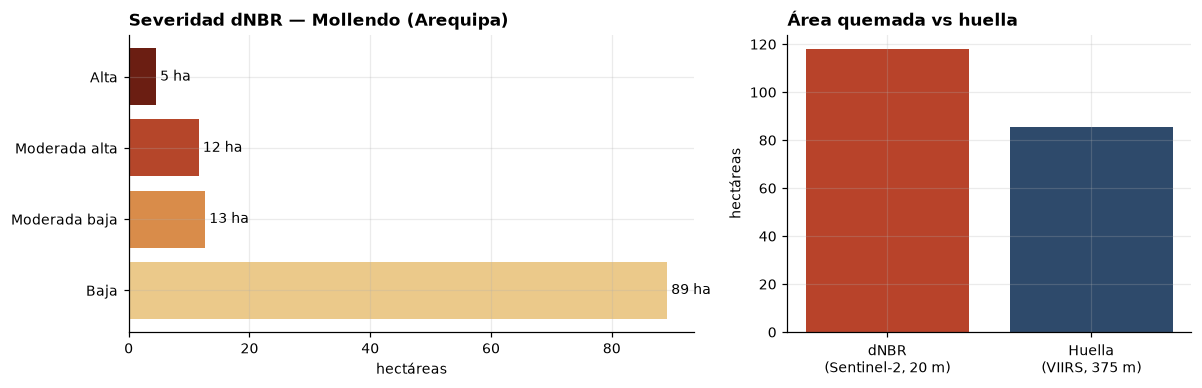

In [21]:
SEV_COL = ["#EBC98A", "#D98C4A", "#B5462A", "#6B1E12"]
if RETOS:
    k = max(RETOS, key=lambda j: RETOS[j]["quemada_ha"]); x = RETOS[k]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.4, 1]})
    vals = [x["sev"].get(s, 0) for s in SEV.values()]
    a1.barh(list(SEV.values()), vals, color=SEV_COL)
    for y, v in enumerate(vals): a1.text(v, y, f" {v:,.0f} ha", va="center")
    a1.set_title(f"Severidad dNBR — {x['dist'].title()} ({x['dep'].title()})", loc="left", fontweight="bold")
    a1.set_xlabel("hectáreas")
    a2.bar(["dNBR\n(Sentinel-2, 20 m)", "Huella\n(VIIRS, 375 m)"],
           [x["quemada_ha"], activos.loc[k, "huella_ha"]], color=["#B8432A", "#2E4A6B"])
    a2.set_title("Área quemada vs huella", loc="left", fontweight="bold"); a2.set_ylabel("hectáreas")
    plt.tight_layout(); fig.savefig("reto_A_dnbr.png", dpi=150); plt.show()

## 6 · Reto C · ¿Qué se quemó? Área quemada × ESA WorldCover
Cada píxel con dNBR ≥ 0.10 se cruza con WorldCover 2021 (10 m). La lectura económica:

- **Pastizal**: forraje para el ganado; se recupera en meses (muchas quemas son para renovar pastos y se escapan).
- **Cultivo**: ingreso perdido para el productor en esta campaña.
- **Bosque**: madera, agua y carbono; tarda décadas en recuperarse.
- **Matorral**: vegetación arbustiva de ladera; protege el suelo de la erosión.

,Bosque,Pastizal,Cultivo,Agua y humedal,Matorral,Otros,Total
incendio,,,,,,,
Paracas (Ica),0.0,0.0,0.0,0.0,0.0,1.0,2.0
Moquegua (Moquegua),0.0,0.0,0.0,0.0,0.0,39.0,39.0
Moquegua (Moquegua) · 214 ha,0.0,0.0,0.0,0.0,0.0,29.0,29.0
Puerto Bermudez (Pasco),0.0,0.0,0.0,0.0,0.0,0.0,0.0
La Joya (Arequipa),0.0,0.0,0.0,0.0,0.0,27.0,27.0
Mollendo (Arequipa),0.0,0.0,0.0,14.0,0.0,103.0,118.0



% del área quemada por cobertura:


,Bosque,Pastizal,Cultivo,Agua y humedal,Matorral,Otros
incendio,,,,,,
Paracas (Ica),15.0,2.0,0.0,8.0,0.0,75.0
Moquegua (Moquegua),0.0,0.0,0.0,0.0,0.0,100.0
Moquegua (Moquegua) · 214 ha,0.0,0.0,0.0,0.0,0.0,100.0
Puerto Bermudez (Pasco),NaN,NaN,NaN,NaN,NaN,NaN
La Joya (Arequipa),0.0,0.0,0.0,0.0,0.0,100.0
Mollendo (Arequipa),0.0,0.0,0.0,12.0,0.0,87.0


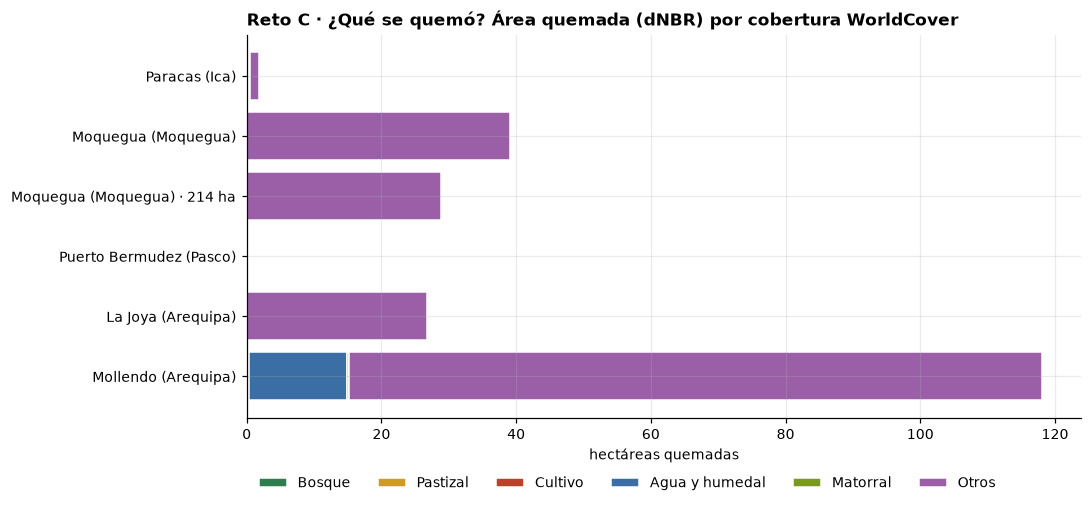

In [22]:
GRUPO = {"Bosque": "Bosque", "Manglar": "Bosque", "Pastizal": "Pastizal", "Cultivo": "Cultivo",
         "Matorral": "Matorral", "Agua": "Agua y humedal", "Humedal": "Agua y humedal"}
ORD_WC = ["Bosque", "Pastizal", "Cultivo", "Agua y humedal", "Matorral", "Otros"]
WC_COL = ["#2E7D4F", "#D09A27", "#B8432A", "#3A6EA5", "#7A9A1F", "#9B5FA8"]   # paleta validada (daltonismo)

filas = []
for k, v in RETOS.items():
    g = dict.fromkeys(ORD_WC, 0.0)
    for clase, ha_ in v["wc"].items():
        g[GRUPO.get(clase, "Otros")] += ha_
    etq = f"{v['dist'].title()} ({v['dep'].title()})"
    if any(f["incendio"] == etq for f in filas):           # dos incendios en el mismo distrito
        etq += f" · {activos.loc[k, 'huella_ha']:,.0f} ha"
    filas.append({"incendio": etq, **g})
reto_c = pd.DataFrame(filas).set_index("incendio") if filas else pd.DataFrame(columns=ORD_WC)
if len(reto_c):
    reto_c["Total"] = reto_c[ORD_WC].sum(axis=1)
    pct_c = reto_c[ORD_WC].div(reto_c.Total, axis=0).mul(100).round(0)
    display(reto_c.round(0))
    print("\n% del área quemada por cobertura:")
    display(pct_c)

    fig, ax = plt.subplots(figsize=(10, 0.55 * len(reto_c) + 1.4))
    izq = np.zeros(len(reto_c))
    for c, col in zip(ORD_WC, WC_COL):
        ax.barh(reto_c.index, reto_c[c], left=izq, color=col, label=c, edgecolor="white", linewidth=1)
        izq += reto_c[c].values
    ax.legend(ncol=6, frameon=False, loc="upper left", bbox_to_anchor=(0, -0.12))
    ax.set_xlabel("hectáreas quemadas"); ax.invert_yaxis()
    ax.set_title("Reto C · ¿Qué se quemó? Área quemada (dNBR) por cobertura WorldCover",
                 loc="left", fontweight="bold")
    plt.tight_layout(); fig.savefig("reto_C_coberturas.png", dpi=150); plt.show()

## 7 · Lluvias sobre suelo quemado (CENEPRED, 22–24 oct 2026)
CENEPRED publicó el *Estudio de escenario de riesgo ante el pronóstico de precipitaciones en la costa
centro y sur* (21/10/2026), basado en el aviso SENAMHI N.° 429: lluvia o llovizna de moderada a extrema
intensidad en la costa de **Arequipa, Callao, Ica, Lima, Moquegua y Tacna** (nivel rojo el 23 y 24).

Por qué importa para los incendios: un área recién quemada pierde la vegetación que sujeta el suelo.
Si además está en **ladera empinada** y llueve, aumenta la probabilidad de **huaycos y erosión**.
Cruzamos: incendio en región con aviso × área quemada (dNBR) × pendiente (SRTM).

Las tablas de CENEPRED se transcriben del reporte (población según Censo 2017, como indica la fuente).

In [23]:
CENEPRED = {
    "aviso": ["AREQUIPA", "CALLAO", "ICA", "LIMA", "MOQUEGUA", "TACNA"],
    # Tabla 2 (movimientos en masa) y Tabla 3 (inundaciones): población expuesta por nivel de riesgo
    "tabla": [
        {"dep": "AREQUIPA", "mm_alto": 12268,  "mm_medio": 124444,  "in_muyalto": 3586,  "in_alto": 70592},
        {"dep": "AYACUCHO", "mm_alto": 0,      "mm_medio": 0,       "in_muyalto": 0,     "in_alto": 4},
        {"dep": "ICA",      "mm_alto": 0,      "mm_medio": 15981,   "in_muyalto": 15934, "in_alto": 223},
        {"dep": "LIMA",     "mm_alto": 110071, "mm_medio": 2154687, "in_muyalto": 2715,  "in_alto": 451655},
        {"dep": "MOQUEGUA", "mm_alto": 0,      "mm_medio": 70932,   "in_muyalto": 19,    "in_alto": 66118},
        {"dep": "TACNA",    "mm_alto": 0,      "mm_medio": 31866,   "in_muyalto": 294,   "in_alto": 290911},
    ],
}
t = pd.DataFrame(CENEPRED["tabla"])
CENEPRED.update(total_mm_alto=int(t.mm_alto.sum()), total_mm_medio=int(t.mm_medio.sum()),
                total_inund_muyalto=int(t.in_muyalto.sum()), total_inund_alto=int(t.in_alto.sum()))

def riesgo_huayco(i):
    if activos.loc[i, "DEPARTAMEN"] not in CENEPRED["aviso"]:
        return ""
    x = RETOS.get(i)
    if not x or x["pend"] is None:
        return "Por evaluar"
    if x["pend"] >= 25 and x["quemada_ha"] >= 50: return "Alto"
    if x["pend"] >= 15: return "Medio"
    return "Bajo"

activos["lluvia"] = activos.DEPARTAMEN.isin(CENEPRED["aviso"])
activos["huayco"] = [riesgo_huayco(i) for i in activos.index]
for i in top.index:
    if activos.loc[i, "huayco"] in ("Alto", "Medio"):
        top.loc[i, "accion"] = (top.loc[i, "accion"].replace("Monitorear", "").strip(" ·")
                                + " · Vigilar huaycos en ladera quemada").strip(" ·")
print(f"incendios activos en regiones con aviso de lluvia: {activos.lluvia.sum()}")
activos[activos.lluvia][["DISTRITO", "DEPARTAMEN", "huella_ha", "huayco"]].sort_values("huella_ha", ascending=False).head(10)

incendios activos en regiones con aviso de lluvia: 8


,DISTRITO,DEPARTAMEN,huella_ha,huayco
incendio,,,,
1149,MOQUEGUA,MOQUEGUA,216.6,Bajo
1148,MOQUEGUA,MOQUEGUA,213.9,Bajo
1151,LA JOYA,AREQUIPA,132.4,Bajo
55,PARACAS,ICA,106.5,Bajo
1150,MOLLENDO,AREQUIPA,85.3,Bajo
1049,PACOCHA,MOQUEGUA,65.6,Por evaluar
1152,LA JOYA,AREQUIPA,57.2,Por evaluar
1644,CANDARAVE,TACNA,33.9,Por evaluar


## 8 · Dashboard interactivo
Se exportan los datos a JSON y se insertan en una plantilla HTML con **Leaflet** (mapa) y **Chart.js**
(gráficos). El tablero tiene filtros por **región y distrito**: todas las cifras, rankings, gráficos y el
mapa se recalculan al elegir. Paleta: cremas, marrones y azules oscuros; los colores de cobertura se
validaron para daltonismo.

La plantilla está en la celda siguiente (es larga: HTML + CSS + JavaScript).

In [24]:
PLANTILLA = r'''<!doctype html>
<html lang="es">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width,initial-scale=1">
<title>Monitor de Incendios Perú</title>
<link rel="preconnect" href="https://fonts.googleapis.com">
<link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700&family=Source+Serif+4:opsz,wght@8..60,600;8..60,700&display=swap" rel="stylesheet">
<link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/leaflet/1.9.4/leaflet.min.css">
<script src="https://cdnjs.cloudflare.com/ajax/libs/leaflet/1.9.4/leaflet.min.js"></script>
<script src="https://cdnjs.cloudflare.com/ajax/libs/Chart.js/4.4.1/chart.umd.min.js"></script>
<link rel="stylesheet" href="https://unpkg.com/maplibre-gl@4.7.1/dist/maplibre-gl.css">
<script src="https://unpkg.com/maplibre-gl@4.7.1/dist/maplibre-gl.js"></script>
<style>
:root{
  --bg:#F4EDE1; --card:#FBF7F0; --line:#E3D8C6; --ink:#2A211B; --mut:#75685C;
  --azul:#1B2A41; --azul2:#2E4A6B; --azul3:#8FA9C4;
  --marron:#7A4E2D; --marron2:#4A2F1D; --ocre:#C08A3E; --fuego:#B8432A;
  --s1:#EBC98A; --s2:#D98C4A; --s3:#B5462A; --s4:#6B1E12;
}
*{box-sizing:border-box}
body{margin:0;background:var(--bg);color:var(--ink);font:15px/1.5 Inter,system-ui,-apple-system,"Segoe UI",sans-serif}
h1,h2,h3{font-family:"Source Serif 4",Georgia,serif;margin:0;color:var(--marron2)}
.wrap{max-width:1200px;margin:0 auto;padding:0 20px}
/* barra superior */
.bar{background:var(--azul);color:#EDE6DA;position:sticky;top:0;z-index:1000;box-shadow:0 2px 10px rgba(0,0,0,.15)}
.bar .wrap{display:flex;flex-wrap:wrap;gap:10px 18px;align-items:center;padding-top:10px;padding-bottom:10px}
.marca{font-weight:700;font-size:15px;letter-spacing:.01em;display:flex;align-items:center;gap:8px;margin-right:auto}
.marca i{width:12px;height:12px;border-radius:50%;border:2.5px solid var(--ocre);display:inline-block}
.bar label{font-size:11px;text-transform:uppercase;letter-spacing:.08em;color:var(--azul3);display:flex;flex-direction:column;gap:2px}
.bar select{font:inherit;font-size:14px;background:#22344F;color:#fff;border:1px solid #3B5478;border-radius:8px;padding:6px 10px;min-width:170px}
.bar .corte{font-size:12px;color:var(--azul3)}
.btn{font:inherit;font-size:13px;border:1px solid #3B5478;background:transparent;color:#EDE6DA;border-radius:8px;padding:6px 12px;cursor:pointer}
.btn:hover{background:#22344F}
nav.secs{background:var(--card);border-bottom:1px solid var(--line)}
nav.secs .wrap{display:flex;gap:20px;overflow-x:auto;white-space:nowrap;padding-top:10px;padding-bottom:10px;font-size:14px}
nav.secs a{color:var(--marron);text-decoration:none;font-weight:500}
nav.secs a:hover{color:var(--fuego)}
/* portada */
.eyebrow{font-size:11.5px;letter-spacing:.1em;text-transform:uppercase;font-weight:700;color:var(--marron);margin:36px 0 8px}
.hero h1{font-size:clamp(28px,4.2vw,42px);line-height:1.12;max-width:900px}
.hero h1 em{font-style:normal;color:var(--fuego)}
.lead{font-size:17px;color:#4B3F35;max-width:820px;margin:14px 0 6px}
.meta{font-size:13px;color:var(--mut)}
.chip{display:inline-block;font-size:12px;background:#EADFCC;color:var(--marron2);border-radius:999px;padding:2px 10px;margin-right:6px}
/* KPIs */
.kpis{display:grid;grid-template-columns:repeat(4,1fr);gap:0;background:var(--card);border:1px solid var(--line);border-radius:14px;overflow:hidden;margin-top:22px}
.kpi{padding:18px 18px 16px;border-right:1px solid var(--line);border-bottom:1px solid var(--line)}
.kpi small{display:block;font-size:11px;letter-spacing:.07em;text-transform:uppercase;font-weight:700;color:var(--mut)}
.kpi b{display:block;font-family:"Source Serif 4",Georgia,serif;font-size:36px;line-height:1.1;margin:8px 0 4px;color:var(--azul)}
.kpi.alerta b{color:var(--fuego)}
.kpi span{font-size:12.5px;color:var(--mut)}
/* tarjetas */
h2{font-size:28px;margin-bottom:6px}
.sub{color:var(--mut);font-size:14px;margin:0 0 14px;max-width:820px}
.grid2{display:grid;grid-template-columns:1fr 1fr;gap:16px}
.grid3{display:grid;grid-template-columns:repeat(3,1fr);gap:16px}
.grid2>*,.grid3>*,.kpis>*{min-width:0}
.card{background:var(--card);border:1px solid var(--line);border-radius:14px;padding:18px}
.card h3{font-size:18px}
.card .sub{font-size:13px;margin:2px 0 10px}
ol.rank{list-style:none;margin:0;padding:0}
ol.rank li{display:flex;gap:12px;padding:11px 4px;border-top:1px solid var(--line);cursor:pointer;border-radius:6px}
ol.rank li:hover{background:#F1E8DA}
ol.rank em{font-style:normal;color:var(--mut);width:20px;font-variant-numeric:tabular-nums}
ol.rank div{flex:1;min-width:0} ol.rank span{color:var(--mut);font-size:13px}
ol.rank p{margin:2px 0 0;font-size:12.5px;color:var(--mut)}
ol.rank strong{white-space:nowrap;color:var(--azul);font-variant-numeric:tabular-nums}
.vacio{color:var(--mut);font-size:13.5px;padding:12px 0}
/* mapa */
#map{height:600px;border-radius:12px;border:1px solid var(--line)}
.leaflet-container{font-family:Inter,system-ui,sans-serif;background:#E9E2D4}
.leyenda{background:rgba(251,247,240,.95);padding:10px 12px;border-radius:10px;border:1px solid var(--line);font-size:12px;line-height:1.7;color:var(--ink);max-width:230px}
.leyenda b{display:block;font-size:11px;text-transform:uppercase;letter-spacing:.06em;color:var(--mut);margin-top:4px}
.sw{display:inline-block;width:12px;height:12px;border-radius:3px;margin-right:6px;vertical-align:-1px}
.sw.c{border-radius:50%}
.nota{font-size:13px;color:var(--mut)}
/* reto */
.retohead{display:flex;flex-wrap:wrap;gap:12px;align-items:end;margin-bottom:14px}
.retohead label{font-size:12px;color:var(--mut);display:flex;flex-direction:column;gap:3px}
.retohead select{font:inherit;padding:8px 10px;border-radius:8px;border:1px solid var(--line);background:#fff;min-width:300px;max-width:100%}
.cifras{display:grid;grid-template-columns:repeat(4,1fr);gap:10px;margin:6px 0 14px}
.cifra{background:#F1E8DA;border-radius:10px;padding:10px 12px}
.cifra small{font-size:11.5px;color:var(--mut);display:block}
.cifra b{font-family:"Source Serif 4",Georgia,serif;font-size:24px;color:var(--azul)}
.cifra b.f{color:var(--fuego)}
.lectura{background:#EADFCC;border-left:4px solid var(--marron);padding:12px 14px;border-radius:8px;font-size:14px;margin-top:12px}
.chartbox{position:relative;height:260px}
/* tablas */
.tabla{overflow-x:auto}
table{width:100%;border-collapse:collapse;font-size:13px}
th,td{text-align:left;padding:9px 8px;border-top:1px solid var(--line);vertical-align:top}
th{font-size:11px;text-transform:uppercase;letter-spacing:.05em;color:var(--mut);font-weight:600;background:#F1E8DA}
td.n,th.n{text-align:right;font-variant-numeric:tabular-nums}
tr.hl td{background:#F3E3CC}
.tag{display:inline-block;font-size:11.5px;border-radius:6px;padding:1px 7px;margin:1px 2px 1px 0;background:#E7DCC9;color:var(--marron2);white-space:nowrap}
.tag.r{background:#F2D2C7;color:#7A2414}.tag.a{background:#DCE5EF;color:var(--azul)}
.nivel{font-weight:600}.nivel.Alto{color:var(--fuego)}.nivel.Medio{color:var(--ocre)}
/* 3D */
#map3d{height:580px;border-radius:12px;border:1px solid var(--line);background:#1B2A41}
.ctl3d{display:flex;flex-wrap:wrap;gap:10px;align-items:center;margin:0 0 12px}
.seg{display:inline-flex;border:1px solid var(--line);border-radius:999px;overflow:hidden;background:#fff}
.seg button{font:inherit;font-size:13px;border:0;background:transparent;padding:6px 14px;cursor:pointer;color:var(--marron2)}
.seg button.on{background:var(--azul);color:#fff}
.linea{display:flex;gap:12px;align-items:center;background:var(--card);border:1px solid var(--line);border-radius:12px;padding:10px 14px;margin-top:12px}
.linea input[type=range]{flex:1;accent-color:var(--fuego)}
.linea .play{width:36px;height:36px;border-radius:50%;border:1px solid var(--line);background:#fff;cursor:pointer;font-size:14px}
.linea b{white-space:nowrap;font-size:13.5px}
.dia{font-size:13px;color:var(--mut);margin-top:8px}
.ley3d{display:flex;flex-wrap:wrap;gap:6px 16px;font-size:12.5px;color:var(--mut);margin-top:8px}
/* deforestación */
.mini{display:grid;grid-template-columns:repeat(4,1fr);gap:10px;margin-bottom:16px}
/* metodología */
.flujo{display:flex;flex-wrap:wrap;gap:10px;margin:8px 0 18px;padding:0;list-style:none;counter-reset:paso}
.flujo li{flex:1 1 150px;background:var(--card);border:1px solid var(--line);border-top:4px solid var(--marron);border-radius:10px;padding:12px;font-size:13px;position:relative;counter-increment:paso}
.flujo li:before{content:counter(paso);font-family:"Source Serif 4",Georgia,serif;font-weight:700;color:var(--fuego);font-size:20px;display:block}
.flujo li b{display:block;color:var(--azul);font-size:14px;margin-bottom:2px}
.formula{font-family:"Source Serif 4",Georgia,serif;font-size:17px;background:#F1E8DA;border-radius:8px;padding:10px 14px;margin:8px 0;color:var(--azul);overflow-x:auto}
.met h3{margin-top:4px}
.met ul{margin:6px 0 0;padding-left:18px;font-size:14px} .met li{margin:4px 0}
footer{margin:40px 0 0;padding:26px 0 40px;border-top:1px solid var(--line);font-size:13px;color:var(--mut)}
footer p{max-width:900px}
section{scroll-margin-top:120px}
@media(max-width:900px){.mini{grid-template-columns:repeat(2,1fr)}#map3d{height:440px}.bar{position:static}.bar select{min-width:0;width:100%}.bar label{flex:1 1 140px}.marca{width:100%}.kpis{grid-template-columns:repeat(2,1fr)}.grid2,.grid3{grid-template-columns:1fr}.cifras{grid-template-columns:repeat(2,1fr)}#map{height:440px}.retohead select{min-width:0;width:100%}}
</style>
</head>
<body>
<div class="bar"><div class="wrap">
  <div class="marca"><i></i>Monitor de Incendios Perú</div>
  <label>Región<select id="selDep"></select></label>
  <label>Distrito<select id="selDist"></select></label>
  <button class="btn" id="btnReset">Todo el Perú</button>
  <div class="corte" id="corte"></div>
</div></div>
<nav class="secs"><div class="wrap">
  <a href="#resumen">Resumen</a><a href="#mapa">Mapa</a><a href="#retoA">Reto A · Área quemada</a>
  <a href="#vista3d">Vista 3D</a><a href="#retoC">Reto C · ¿Qué se quemó?</a><a href="#prioridad">Atención prioritaria</a>
  <a href="#lluvias">Lluvias · CENEPRED</a><a href="#deforestacion">Deforestación</a><a href="#decidir">Para decidir</a><a href="#metodologia">Metodología</a><a href="#fuentes">Fuentes</a>
</div></nav>

<main class="wrap">
<section id="resumen" class="hero">
  <div class="eyebrow">Parte de situación · incendios forestales · temporada 2026</div>
  <h1 id="titular"></h1>
  <p class="lead" id="bajada"></p>
  <p class="meta" id="metaFuentes"></p>
  <div class="kpis" id="kpis"></div>
</section>

<section id="mapa">
  <div class="eyebrow">Mapa interactivo</div>
  <h2>Dónde está el fuego y qué tiene cerca</h2>
  <p class="sub">Haga clic en un distrito para filtrar todo el tablero. En el control de capas (arriba a la derecha) puede cambiar a vista satélite y prender las construcciones expuestas.</p>
  <div id="map"></div>
  <p class="nota" id="notaMapa"></p>
</section>

<section id="retoA">
  <div class="eyebrow">Reto A · Otro incendio</div>
  <h2>¿Cuánto se quemó realmente? Área quemada con dNBR</h2>
  <p class="sub">Comparamos imágenes Sentinel-2 de antes y después del fuego. El índice NBR cae cuando la vegetación se quema; su diferencia (dNBR) mide la severidad. La huella VIIRS cuenta píxeles de 375 m con fuego; el dNBR mide a 20 m lo que de verdad cambió.</p>
  <div class="card">
    <div class="retohead"><label>Incendio analizado<select id="selReto"></select></label><button class="btn" id="btnVerReto" style="color:var(--azul);border-color:var(--line)">Ver en el mapa</button></div>
    <h3 id="retoTitulo"></h3><p class="sub" id="retoSub"></p>
    <div class="cifras" id="retoCifras"></div>
    <div class="grid2">
      <div><h3 style="font-size:15px">Severidad del área quemada (dNBR)</h3><p class="sub">hectáreas por nivel · umbrales USGS (Key y Benson)</p><div class="chartbox"><canvas id="chSev"></canvas></div></div>
      <div><h3 style="font-size:15px">Área quemada dNBR vs huella VIIRS</h3><p class="sub">hectáreas</p><div class="chartbox"><canvas id="chComp"></canvas></div></div>
    </div>
    <div class="lectura" id="retoLectura"></div>
  </div>
</section>

<section id="vista3d">
  <div class="eyebrow">Seguimiento de un incendio</div>
  <h2>El incendio, día por día, sobre el terreno</h2>
  <p class="sub">Relieve real (AWS Terrain Tiles) con la imagen satelital encima. Mueva la línea de tiempo para ver cómo avanzó el fuego. Arrastre para mover, clic derecho (o dos dedos) para girar e inclinar, rueda para acercar.</p>
  <div class="ctl3d">
    <label class="nota" style="display:flex;flex-direction:column;gap:3px">Incendio<select id="selReto3" style="font:inherit;padding:7px 10px;border-radius:8px;border:1px solid var(--line);background:#fff;max-width:100%"></select></label>
    <div class="seg" id="modo3"><button data-m="sat" class="on">Satélite</button><button data-m="fc">Infrarrojo (Sentinel-2)</button><button data-m="dnbr">Severidad dNBR</button></div>
  </div>
  <div id="map3d"></div>
  <div class="linea"><button class="play" id="play3" aria-label="Reproducir">▶</button><input type="range" id="dia3" min="0" max="0" value="0"><b id="diaTxt"></b></div>
  <div class="ley3d"><span><span class="sw c" style="background:#E8452B"></span>Focos del día elegido</span><span><span class="sw c" style="background:#F2A541"></span>Focos de 1 y 2 días antes</span><span><span class="sw c" style="background:#8C7B6B"></span>Focos anteriores</span><span><span class="sw" style="background:none;border:2px solid #FBF7F0;outline:1px solid #75685C"></span>Borde del área quemada (dNBR)</span></div>
  <p class="dia" id="info3"></p>
</section>

<section id="retoC">
  <div class="eyebrow">Reto C · ¿Qué se quemó?</div>
  <h2>Bosque, pastizal o cultivo: el área quemada cruzada con WorldCover</h2>
  <p class="sub">Cada píxel quemado (dNBR ≥ 0.10) se cruza con el mapa de cobertura ESA WorldCover (10 m). Importa para la economía: un pastizal quemado se recupera en meses; un cultivo es ingreso perdido; un bosque tarda décadas.</p>
  <div class="grid2">
    <div class="card"><h3 id="cTitulo">Incendio seleccionado</h3><p class="sub">hectáreas quemadas por cobertura</p><div class="chartbox"><canvas id="chWC"></canvas></div></div>
    <div class="card"><h3>Todos los incendios analizados en la selección</h3><p class="sub" id="cSubAgg"></p><div class="chartbox"><canvas id="chWCagg"></canvas></div></div>
  </div>
  <div class="card tabla" style="margin-top:16px"><h3>Tabla: área quemada por cobertura (ha)</h3><p class="sub">Incendios con análisis dNBR dentro del filtro actual</p><table id="tabWC"></table></div>
  <div class="lectura" id="cLectura"></div>
</section>

<section id="prioridad">
  <div class="eyebrow">Para decidir hoy</div>
  <h2>Atención prioritaria</h2>
  <p class="sub">Cuatro lecturas de los incendios activos del filtro. Haga clic en una fila para ubicarla en el mapa.</p>
  <div class="grid2">
    <div class="card"><h3>Se extienden más rápido</h3><p class="sub">Huella nueva en las últimas 24 h</p><ol class="rank" id="rkRapido"></ol></div>
    <div class="card"><h3>Más población cerca</h3><p class="sub">Habitantes a ≤ 5 km · WorldPop ajustado al Censo 2025</p><ol class="rank" id="rkPob"></ol></div>
    <div class="card"><h3>Más construcciones expuestas</h3><p class="sub">Edificaciones Open Buildings a ≤ 1 km del fuego</p><ol class="rank" id="rkEdif"></ol></div>
    <div class="card"><h3>Más cultivos y pastos cerca</h3><p class="sub">Hectáreas a ≤ 1 km · ESA WorldCover</p><ol class="rank" id="rkAgro"></ol></div>
  </div>
</section>

<section id="lluvias">
  <div class="eyebrow">Riesgo compuesto · CENEPRED</div>
  <h2>Lluvias del 22 al 24 de octubre sobre suelo recién quemado</h2>
  <p class="sub" id="lluviaSub"></p>
  <div class="grid2">
    <div class="card"><h3>Incendios en regiones con aviso de lluvia</h3><p class="sub">Ladera quemada + lluvia = más probabilidad de huaycos y erosión. Pendiente mediana del área quemada (SRTM).</p><div class="tabla"><table id="tabLluvia"></table></div></div>
    <div class="card"><h3>Escenario de riesgo CENEPRED por región</h3><p class="sub">Elementos expuestos según nivel de riesgo (población: Censo 2017)</p><div class="tabla"><table id="tabCenepred"></table></div></div>
  </div>
</section>

<section id="deforestacion">
  <div class="eyebrow">Deforestación · datos oficiales</div>
  <h2>Bosque, pérdida de bosque y fuego</h2>
  <p class="sub">Cifras oficiales del Programa Nacional de Conservación de Bosques para la Mitigación del Cambio Climático (MINAM), plataforma Geobosques: bosque húmedo amazónico que queda en cada distrito y cuánto se perdió cada año. Se cruzan con los focos de calor y las alertas tempranas de deforestación de la última semana.</p>
  <div class="mini" id="defKpis"></div>
  <div class="grid2">
    <div class="card"><h3>Pérdida de bosque por año</h3><p class="sub" id="defSub"></p><div class="chartbox"><canvas id="chGeob"></canvas></div></div>
    <div class="card"><h3>Dónde cae el fuego</h3><p class="sub" id="bSub"></p><div class="chartbox"><canvas id="chBosque"></canvas></div></div>
  </div>
  <div class="card tabla" style="margin-top:16px"><h3>Distritos con fuego y bosque</h3><p class="sub">Geobosques (MINAM) · ordenados por pérdida del último año · focos de 7 días</p><table id="tabGeob"></table></div>
  <div class="grid2" style="margin-top:16px">
    <div class="card"><h3>Pérdida de bosque cerca de los incendios prioritarios</h3><p class="sub" id="pSub"></p><div class="chartbox"><canvas id="chPerdida"></canvas></div></div>
    <div class="card tabla" id="cardSerfor"><h3>Capa SERFOR</h3><p class="sub" id="serforSub"></p><table id="tabSerfor"></table></div>
  </div>
  <div class="lectura" id="defLectura"></div>
</section>

<section id="decidir">
  <div class="eyebrow">Para decidir</div>
  <h2>Acción sugerida por incendio</h2>
  <p class="sub">Reglas: alerta a la población (≥ 500 personas a ≤ 1 km o ≥ 50 construcciones a ≤ 500 m) · proteger cultivos (≥ 20 ha a ≤ 1 km) · riesgo ganadero (≥ 100 ha de pastos) · proteger bosque (≥ 50 ha de bosque en la huella) · fiscalizar posible deforestación · vigilar huaycos (aviso de lluvia sobre ladera quemada).</p>
  <div class="card tabla"><table id="tabDecidir"></table></div>
</section>

<section id="metodologia" class="met">
  <div class="eyebrow">Cómo se hizo</div>
  <h2>Metodología</h2>
  <p class="sub">Todo el tablero se genera con un notebook de Python (geopandas, scipy, Earth Engine). Estos son los pasos, las fórmulas y los criterios.</p>
  <ol class="flujo">
    <li><b>Focos de calor</b>VIIRS S-NPP, NOAA-20 y NOAA-21 (FIRMS), últimos 7 días; se quitan los de confianza baja y se dejan los que caen en distritos del Perú.</li>
    <li><b>Incendios</b>Focos a ≤ 1 km y ≤ 48 h se unen (componentes conexos de un grafo). Activo: ≥ 3 focos y uno en 24 h.</li>
    <li><b>Huella</b>Unión de cuadrados de 375 m alrededor de cada foco (EPSG:24891, en metros).</li>
    <li><b>Área quemada</b>dNBR con Sentinel-2 antes/después; severidad por umbrales USGS (Reto A).</li>
    <li><b>¿Qué se quemó?</b>Píxeles quemados × ESA WorldCover (Reto C).</li>
    <li><b>Exposición</b>Construcciones, población, cultivos, bosque y deforestación alrededor del fuego.</li>
    <li><b>Decisión</b>Índice de prioridad, acciones sugeridas y cruce con lluvias de CENEPRED.</li>
  </ol>
  <div class="grid2">
    <div class="card">
      <h3>Fórmulas</h3>
      <div class="formula">NBR = (B8 − B12) / (B8 + B12)</div>
      <p class="nota">B8: infrarrojo cercano; B12: infrarrojo de onda corta. La vegetación sana tiene NBR alto; al quemarse, baja.</p>
      <div class="formula">dNBR = NBR<sub>antes</sub> − NBR<sub>después</sub></div>
      <p class="nota">Antes: mediana de escenas limpias de 75 a 2 días previos al inicio. Después: píxel limpio más reciente de los últimos 20 días. Nubes y humo: Cloud Score+ ≥ 0.60. Solo dentro de 1 km de la huella.</p>
      <div class="formula">Prioridad = 0.65 · base + 15 · P(construcciones) + 20 · P(población)</div>
      <p class="nota">base = 100 · [0.4 · P(huella) + 0.3 · P(focos 24 h) + 0.3 · P(FRP)]; P(x) = percentil del incendio entre los activos.</p>
      <div class="formula">Población<sub>censo</sub> = WorldPop · (Censo 2025 / Σ WorldPop)</div>
    </div>
    <div class="card">
      <h3>Severidad del área quemada</h3>
      <table><tr><th>dNBR</th><th>Severidad</th></tr>
        <tr><td>0.10 – 0.27</td><td><span class="sw" style="background:#EBC98A"></span>Baja</td></tr>
        <tr><td>0.27 – 0.44</td><td><span class="sw" style="background:#D98C4A"></span>Moderada baja</td></tr>
        <tr><td>0.44 – 0.66</td><td><span class="sw" style="background:#B5462A"></span>Moderada alta</td></tr>
        <tr><td>&gt; 0.66</td><td><span class="sw" style="background:#6B1E12"></span>Alta</td></tr></table>
      <h3 style="margin-top:16px">Criterios de decisión</h3>
      <ul>
        <li><b>Alerta a la población:</b> ≥ 500 personas a ≤ 1 km o ≥ 50 construcciones a ≤ 500 m.</li>
        <li><b>Proteger cultivos:</b> ≥ 20 ha de cultivo a ≤ 1 km. <b>Riesgo ganadero:</b> ≥ 100 ha de pastos.</li>
        <li><b>Proteger bosque:</b> ≥ 50 ha de bosque en pie dentro de la huella.</li>
        <li><b>Fiscalizar deforestación:</b> ≥ 40 % de los focos en tierra deforestada en los últimos 5 años.</li>
        <li><b>Huayco:</b> región con aviso de lluvia; alto si la pendiente mediana del área quemada es ≥ 25° y hay ≥ 50 ha quemadas.</li>
      </ul>
    </div>
  </div>
  <div class="card tabla" style="margin-top:16px">
    <h3>Fuentes de datos</h3>
    <table>
      <tr><th>Dato</th><th>Fuente</th><th>Resolución</th><th>Fecha</th><th>Uso en el tablero</th></tr>
      <tr><td>Focos de calor</td><td>NASA FIRMS · VIIRS</td><td>375 m</td><td>últimos 7 días</td><td>incendios, huella, mapa</td></tr>
      <tr><td>Imágenes ópticas</td><td>Copernicus Sentinel-2 L2A</td><td>10–20 m</td><td>antes y después de cada incendio</td><td>dNBR, falso color, 3D</td></tr>
      <tr><td>Cobertura del suelo</td><td>ESA WorldCover</td><td>10 m</td><td>2021</td><td>Reto C, cultivos y pastos</td></tr>
      <tr><td>Construcciones</td><td>Google Open Buildings v3</td><td>huellas</td><td>imágenes hasta 2023</td><td>construcciones expuestas</td></tr>
      <tr><td>Población</td><td>WorldPop + INEI Censos Nacionales 2025</td><td>100 m</td><td>2020, escalado a 2025</td><td>personas a ≤ 1 y 5 km</td></tr>
      <tr><td>Bosque y pérdida (oficial)</td><td>MINAM · PNCBMCC · Geobosques</td><td>distrito</td><td>2001 – último año publicado</td><td>sección Deforestación</td></tr>
      <tr><td>Alertas de deforestación</td><td>Geobosques (alertas tempranas)</td><td>puntos</td><td>última semana</td><td>mapa y Deforestación</td></tr>
      <tr><td>Bosque global</td><td>Hansen / UMD Global Forest Change</td><td>30 m</td><td>2001 – último año</td><td>clase de bosque de cada foco</td></tr>
      <tr><td>Relieve</td><td>SRTM · AWS Terrain Tiles</td><td>30 m</td><td>—</td><td>pendiente, vista 3D</td></tr>
      <tr><td>Lluvias</td><td>CENEPRED · SENAMHI aviso N.° 429</td><td>departamento</td><td>22–24 oct 2026</td><td>riesgo de huaycos</td></tr>
      <tr><td>Límites</td><td>INEI</td><td>distrito</td><td>—</td><td>filtros y mapa</td></tr>
    </table>
  </div>
  <div class="card" style="margin-top:16px">
    <h3>Limitaciones</h3>
    <ul>
      <li>Un foco de calor no distingue incendio forestal de quema agrícola: por eso se cruza con cobertura y bosque.</li>
      <li>La huella VIIRS sobreestima en incendios pequeños (cada píxel ≈ 14 ha) y subestima lo que arde entre pasadas o bajo humo.</li>
      <li>El dNBR depende de imágenes sin nubes; en la Amazonía el humo puede dejar pocas escenas (se informa el % de píxeles válidos).</li>
      <li>WorldCover es de 2021 y Open Buildings usa imágenes hasta 2023: cambios recientes no aparecen.</li>
      <li>La población es una estimación (WorldPop) ajustada al total censal, no un conteo por vivienda.</li>
      <li>Geobosques cubre el bosque húmedo amazónico: los incendios de puna y costa quedan fuera de esas cifras.</li>
      <li>Exposición no es daño: las cifras indican qué podría verse afectado.</li>
    </ul>
  </div>
</section>

<footer id="fuentes">
  <p><b>Foco de calor:</b> píxel de 375 m donde un satélite VIIRS (S-NPP, NOAA-20, NOAA-21; NASA FIRMS) detectó fuego. <b>Incendio activo:</b> grupo de focos vecinos (≤ 1 km y ≤ 48 h) con ≥ 3 focos y al menos uno en las últimas 24 h. <b>Huella:</b> unión de los píxeles con fuego; no es el área quemada oficial.</p>
  <p><b>Área quemada (Reto A):</b> dNBR = NBR<sub>antes</sub> − NBR<sub>después</sub> con Sentinel-2 L2A (nubes enmascaradas con Cloud Score+). Antes: mediana de 75 a 2 días previos al inicio del incendio; después: el píxel limpio más reciente de los últimos 20 días. Severidad: baja 0.10–0.27, moderada baja 0.27–0.44, moderada alta 0.44–0.66, alta &gt; 0.66. Se mide dentro de 1 km de la huella VIIRS. <b>Cobertura (Reto C):</b> ESA WorldCover 2021, 10 m.</p>
  <p><b>Construcciones:</b> Google Open Buildings v3. <b>Población:</b> WorldPop 2020 reescalado al total de los Censos Nacionales 2025 (INEI). <b>Bosques:</b> Geobosques (MINAM-PNCBMCC) y Hansen/UMD Global Forest Change. <b>Capa forestal opcional:</b> SERFOR (GEOSERFOR). <b>Lluvias:</b> CENEPRED, Estudio de escenario de riesgo ante el pronóstico de precipitaciones en la costa centro y sur, 22–24 oct 2026 (aviso SENAMHI N.° 429). <b>Límites:</b> INEI.</p>
  <p>Exposición no es daño: estas cifras indican qué podría verse afectado. Las capas satelitales de la vista 3D (infrarrojo y severidad dNBR) se sirven desde Earth Engine y caducan algunas horas después de generar el tablero; vuelva a ejecutar el notebook para renovarlas.</p>
  <p>Elaborado por Lory Acosta · Curso de Python · Tarea clase 5 (retos A y C).</p>
</footer>
</main>

<script>
const D = __DATOS__;

/* ---------- utilidades ---------- */
const $ = id => document.getElementById(id);
const fmt = (x, d = 0) => (x === null || x === undefined || Number.isNaN(+x)) ? "—"
  : Number(x).toLocaleString("es-PE", {minimumFractionDigits: d, maximumFractionDigits: d});
const tit = s => (s || "").toLowerCase().replace(/(^|\s|-)(\S)/g, (m, a, b) => a + b.toUpperCase());
const pct = (a, b) => b ? Math.round(100 * a / b) + " %" : "—";
const sum = (arr, k) => arr.reduce((s, r) => s + (+r[k] || 0), 0);
const sumN = (arr, k) => arr.some(r => r[k] !== null && r[k] !== undefined) ? sum(arr, k) : null;   // null = dato no calculado
const S = {dep: "", dist: "", reto: null};
const enFiltro = (dep, dist) => (!S.dep || dep === S.dep) && (!S.dist || dist === S.dist);
const lugar = () => S.dist ? `en ${tit(S.dist)} (${tit(S.dep)})` : S.dep ? `en ${tit(S.dep)}` : "en el Perú";

const COL = {
  sev: {"Baja": "#EBC98A", "Moderada baja": "#D98C4A", "Moderada alta": "#B5462A", "Alta": "#6B1E12"},
  wc: {"Bosque": "#2E7D4F", "Pastizal": "#D09A27", "Cultivo": "#B8432A", "Agua y humedal": "#3A6EA5", "Matorral": "#7A9A1F", "Otros": "#9B5FA8"},
  bosque: {"Bosque en pie": "#2E7D4F", "Deforestación antigua": "#D09A27", "Deforestación reciente": "#B8432A", "Sin bosque": "#9C8F82"},
  f24: "#B8432A", f7: "#D9A441", azul: "#1B2A41", azul2: "#2E4A6B", marron: "#7A4E2D"
};
const ORD_WC = ["Bosque", "Pastizal", "Cultivo", "Agua y humedal", "Matorral", "Otros"];
const ORD_SEV = ["Baja", "Moderada baja", "Moderada alta", "Alta"];
const ORD_BOS = ["Bosque en pie", "Deforestación antigua", "Deforestación reciente", "Sin bosque"];
const CLS = ["Sin bosque", "Bosque en pie", "Deforestación reciente", "Deforestación antigua"];
const agrupaWC = wc => {            // WorldCover -> 6 grupos legibles
  const g = Object.fromEntries(ORD_WC.map(k => [k, 0]));
  for (const [k, v] of Object.entries(wc || {})) {
    if (k === "Bosque" || k === "Manglar") g["Bosque"] += v;
    else if (k === "Pastizal") g["Pastizal"] += v;
    else if (k === "Cultivo") g["Cultivo"] += v;
    else if (k === "Matorral") g["Matorral"] += v;
    else if (k === "Agua" || k === "Humedal") g["Agua y humedal"] += v;
    else g["Otros"] += v;
  }
  return g;
};

Chart.defaults.font.family = "Inter, system-ui, sans-serif";
Chart.defaults.font.size = 12;
Chart.defaults.color = "#75685C";
Chart.defaults.plugins.legend.labels.boxWidth = 12;
Chart.defaults.plugins.tooltip.backgroundColor = "#1B2A41";
const charts = {};
function barra(id, labels, data, colors, opts = {}) {
  if (charts[id]) charts[id].destroy();
  charts[id] = new Chart($(id), {
    type: "bar",
    data: {labels, datasets: [{data, backgroundColor: colors, borderRadius: 4, borderSkipped: false,
                               borderColor: "#FBF7F0", borderWidth: 1, maxBarThickness: 38}]},
    options: Object.assign({
      indexAxis: "y", responsive: true, maintainAspectRatio: false,
      plugins: {legend: {display: false},
                tooltip: {callbacks: {label: c => " " + fmt(c.parsed.x ?? c.parsed.y) + " ha"}}},
      scales: {x: {grid: {color: "#ECE3D4"}, border: {display: false}},
               y: {grid: {display: false}, border: {display: false}}},
      layout: {padding: {right: 46}},
      animation: {duration: 300}
    }, opts),
    plugins: [{id: "etiquetas", afterDatasetsDraw(ch) {      // etiqueta directa de cada barra
      const {ctx} = ch; ctx.save(); ctx.font = "600 12px Inter, sans-serif"; ctx.fillStyle = "#2A211B";
      ch.getDatasetMeta(0).data.forEach((b, i) => {
        const v = ch.data.datasets[0].data[i]; if (!v) return;
        if (ch.options.indexAxis === "y") { ctx.textBaseline = "middle"; ctx.fillText(fmt(v), b.x + 6, b.y); }
        else { ctx.textAlign = "center"; ctx.fillText(fmt(v), b.x, b.y - 8); }
      }); ctx.restore();
    }}]
  });
}

/* ---------- datos derivados ---------- */
const INC = D.inc;
const RETOS = D.retos;
const porId = Object.fromEntries(INC.map(r => [r.id, r]));
const deps = [...new Set(D.focos.map(f => f[4]))].sort();

/* ---------- mapa ---------- */
const map = L.map("map", {preferCanvas: true, scrollWheelZoom: false}).setView([-9.4, -75.2], 5);
map.on("focus", () => map.scrollWheelZoom.enable());
const base = {
  "Mapa claro": L.tileLayer("https://{s}.basemaps.cartocdn.com/light_all/{z}/{x}/{y}{r}.png",
                            {attribution: "© OpenStreetMap © CARTO", subdomains: "abcd", maxZoom: 19}).addTo(map),
  "Satélite": L.tileLayer("https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
                          {attribution: "Esri World Imagery", maxZoom: 19})
};
const lyr = {
  aviso: L.geoJSON(D.deps, {
    filter: f => f.properties.aviso,
    style: {color: COL.azul2, weight: 1.5, dashArray: "4 4", fillColor: "#3A6EA5", fillOpacity: 0.10},
    onEachFeature: (f, l) => l.bindTooltip(`<b>${tit(f.properties.dep)}</b><br>Aviso de lluvia 22–24 oct (CENEPRED / SENAMHI N.° 429)`)
  }),
  deps: L.geoJSON(D.deps, {style: {color: "#7A4E2D", weight: 0.8, fill: false, opacity: 0.6}, interactive: false}),
  dist: L.geoJSON(null),
  f7: L.layerGroup(), f24: L.layerGroup(), inc: L.layerGroup(),
  quem: L.geoJSON(null), edif: L.geoJSON(null),
  dnbr: L.layerGroup(), fc: L.layerGroup()
};
// área quemada (polígonos dNBR)
for (const r of Object.values(RETOS)) {
  if (r.geo) lyr.quem.addData(r.geo);
}
lyr.quem.setStyle(f => ({color: COL.sev[f.properties.sev], weight: 0.4, fillColor: COL.sev[f.properties.sev], fillOpacity: 0.75}));
lyr.quem.eachLayer(l => l.bindTooltip(`Área quemada · severidad <b>${l.feature.properties.sev}</b>`));
if (D.edif) {
  lyr.edif.addData(D.edif);
  lyr.edif.setStyle(f => ({color: f.properties.exp === "Alta" ? "#B8432A" : "#D9A441", weight: 1, fillOpacity: 0.8}));
  lyr.edif.eachLayer(l => l.bindTooltip(`Construcción · exposición ${l.feature.properties.exp}<br>${fmt(l.feature.properties.d)} m del fuego`));
}
lyr.focos = L.layerGroup([lyr.f7, lyr.f24]);
const overlays = {
  "Focos de calor (24 h y 7 días)": lyr.focos,
  "Incendios activos > 100 ha": lyr.inc,
  "Distritos: focos en 7 días": lyr.dist,
  "Área quemada (Sentinel-2)": lyr.quem,
  "Aviso de lluvias CENEPRED": lyr.aviso,
  "Construcciones expuestas (acerque el mapa)": lyr.edif
};
[lyr.dist, lyr.focos, lyr.inc, lyr.quem, lyr.aviso].forEach(l => l.addTo(map));
L.control.layers(base, overlays, {collapsed: window.innerWidth < 900}).addTo(map);
// construcciones: solo se dibujan con zoom >= 12 (si no, son puntos ilegibles)
map.on("zoomend overlayadd", () => { if (map.hasLayer(lyr.edif) && map.getZoom() < 12) $("notaMapa").textContent = "Acerque el mapa (zoom 12 o más) para ver las construcciones."; else if (D.meta.ee_ok) $("notaMapa").textContent = ""; });
L.control.scale({imperial: false}).addTo(map);
const leg = L.control({position: "bottomleft"});
leg.onAdd = () => { const d = L.DomUtil.create("div", "leyenda"); d.id = "leyenda"; return d; };
leg.addTo(map);

function escalaDist(n, max) {
  if (!n) return "#00000000";
  const t = Math.log1p(n) / Math.log1p(max);
  const ramp = ["#F3E2C3", "#E3BE86", "#C98F52", "#9C5F33", "#5E3A22"];
  return ramp[Math.min(4, Math.floor(t * 5))];
}

function pintaMapa(focos, incs) {
  lyr.f7.clearLayers(); lyr.f24.clearLayers(); lyr.inc.clearLayers();
  for (const f of focos) {
    const es24 = f[2] <= 24;
    L.circleMarker([f[0], f[1]], {radius: es24 ? 3 : 2.2, stroke: false, fillOpacity: es24 ? 0.9 : 0.65,
      fillColor: es24 ? COL.f24 : COL.f7})
      .bindTooltip(`${tit(f[5])} (${tit(f[4])})<br>hace ${fmt(f[2])} h · FRP ${fmt(f[3], 1)} MW`)
      .addTo(es24 ? lyr.f24 : lyr.f7);
  }
  for (const r of incs.filter(r => r.ha >= 100)) {
    L.circleMarker([r.lat, r.lon], {radius: 6 + Math.sqrt(r.ha) / 4, color: COL.fuego || "#B8432A", weight: 2, fill: false})
      .bindTooltip(`<b>${tit(r.dist)}</b> · ${tit(r.dep)}<br>${fmt(r.ha)} ha de huella · ${r.f24} focos en 24 h` +
                   (RETOS[r.id] ? `<br>dNBR: ${fmt(RETOS[r.id].quemada_ha)} ha quemadas` : ""))
      .on("click", () => { if (RETOS[r.id]) eligeReto(r.id, true); })
      .addTo(lyr.inc);
  }
  // coroplético por distrito
  const cuenta = {};
  for (const f of D.focos) { const k = f[4] + "|" + f[5]; cuenta[k] = (cuenta[k] || 0) + 1; }
  const max = Math.max(...Object.values(cuenta), 1);
  lyr.dist.clearLayers();
  lyr.dist.addData(D.distritos);
  lyr.dist.eachLayer(l => {
    const p = l.feature.properties, k = p.dep + "|" + p.dist, n = cuenta[k] || 0;
    const activo = enFiltro(p.dep, p.dist);
    l.setStyle({color: activo && S.dist === p.dist ? COL.azul : "#FBF7F0", weight: activo && S.dist === p.dist ? 2.5 : 0.5,
                fillColor: escalaDist(n, max), fillOpacity: activo ? 0.6 : 0.15});
    l.bindTooltip(`<b>${tit(p.dist)}</b> · ${tit(p.dep)}<br>${fmt(n)} focos en 7 días`);
    l.on("click", () => { S.dep = p.dep; S.dist = p.dist; sincronizaSelects(); render(true); });
  });
  lyr.dist.bringToBack();
  $("leyenda").innerHTML = `<b>Focos de calor</b>
    <span class="sw c" style="background:${COL.f24}"></span>Últimas 24 h<br>
    <span class="sw c" style="background:${COL.f7}"></span>De 1 a 7 días<br>
    <span class="sw c" style="border:2px solid #B8432A;background:none"></span>Incendio activo &gt; 100 ha
    <b>Área quemada dNBR</b>${ORD_SEV.map(s => `<span class="sw" style="background:${COL.sev[s]}"></span>${s}`).join("<br>")}
    <b>Otras capas</b><span class="sw" style="background:#3A6EA533;border:1.5px dashed ${COL.azul2}"></span>Aviso de lluvias (22–24 oct)<br>
    <span class="sw" style="background:#9C5F33"></span>Distritos: más focos = más oscuro`;
}

function encuadra() {
  let capa = null;
  if (S.dist) lyr.dist.eachLayer(l => { if (l.feature.properties.dist === S.dist && l.feature.properties.dep === S.dep) capa = l; });
  else if (S.dep) { const g = L.geoJSON(D.deps, {filter: f => f.properties.dep === S.dep}); if (g.getLayers().length) capa = g; }
  if (capa) map.fitBounds(capa.getBounds(), {padding: [20, 20], maxZoom: 11});
  else map.setView([-9.4, -75.2], 5);
}

/* ---------- filtros ---------- */
function sincronizaSelects() {
  $("selDep").innerHTML = `<option value="">Todas las regiones</option>` +
    deps.map(d => `<option value="${d}" ${d === S.dep ? "selected" : ""}>${tit(d)}</option>`).join("");
  const dists = [...new Set(D.focos.filter(f => f[4] === S.dep).map(f => f[5]))].sort();
  $("selDist").innerHTML = `<option value="">${S.dep ? "Todos los distritos" : "Elija una región"}</option>` +
    dists.map(d => `<option value="${d}" ${d === S.dist ? "selected" : ""}>${tit(d)}</option>`).join("");
  $("selDist").disabled = !S.dep;
}
$("selDep").onchange = e => { S.dep = e.target.value; S.dist = ""; sincronizaSelects(); render(true); };
$("selDist").onchange = e => { S.dist = e.target.value; render(true); };
$("btnReset").onclick = () => { S.dep = ""; S.dist = ""; sincronizaSelects(); render(true); };

/* ---------- secciones ---------- */
function kpis(focos, incs) {
  const n24 = focos.filter(f => f[2] <= 24).length;
  const conRetos = incs.filter(r => RETOS[r.id]);
  const quem = conRetos.reduce((s, r) => s + (RETOS[r.id].quemada_ha || 0), 0);
  const fb = focos.filter(f => f[6] >= 0);
  const enBosque = fb.filter(f => f[6] === 1).length;
  const tiles = [
    ["Incendios activos > 100 ha", fmt(incs.filter(r => r.ha > 100).length), `de ${fmt(incs.length)} ${incs.length === 1 ? "incendio activo" : "incendios activos"} con 3 o más focos`, true],
    ["Focos de calor, 24 h", fmt(n24), `${fmt(focos.length)} focos en 7 días`, false],
    ["Huella de incendios activos", fmt(sum(incs, "ha")) + " ha", `+${fmt(sum(incs, "nueva"))} ha nuevas en 24 h`, false],
    ["Área quemada (dNBR)", conRetos.length ? fmt(quem) + " ha" : "—", conRetos.length ? `en ${conRetos.length} ${conRetos.length === 1 ? "incendio analizado" : "incendios analizados"} con Sentinel-2` : "ningún incendio analizado en el filtro", true],
    ["Personas a ≤ 5 km", fmt(sumN(incs, "pob5")), sumN(incs, "pob5") === null ? "sin dato (requiere Earth Engine)" : "WorldPop ajustado al Censo 2025", false],
    ["Construcciones a ≤ 1 km", fmt(sumN(incs, "edif1k")), sumN(incs, "edif1k") === null ? "sin dato (requiere Earth Engine)" : `${fmt(sumN(incs, "edif500"))} a ≤ 500 m · Open Buildings`, false],
    ["Cultivos a ≤ 1 km", sumN(incs, "cult1") === null ? "—" : fmt(sumN(incs, "cult1")) + " ha", sumN(incs, "cult1") === null ? "sin dato (requiere Earth Engine)" : `+ ${fmt(sumN(incs, "past1"))} ha de pastos`, false],
    ["Focos en bosque en pie", fb.length ? pct(enBosque, fb.length) : "—", fb.length ? `${pct(fb.filter(f => f[6] === 2).length, fb.length)} en deforestación reciente` : "sin dato de bosques", false],
  ];
  $("kpis").innerHTML = tiles.map(([k, v, d, a]) => `<div class="kpi ${a ? "alerta" : ""}"><small>${k}</small><b>${v}</b><span>${d}</span></div>`).join("");
}

function portada(focos, incs) {
  const n100 = incs.filter(r => r.ha > 100).length;
  const lider = [...incs].sort((a, b) => b.prio - a.prio)[0];
  const nI = incs.length;
  const sup = n100 === 0 ? "ninguno supera las 100 ha" : n100 === 1 ? "1 supera las 100 ha" : `${fmt(n100)} superan las 100 ha`;
  $("titular").innerHTML = nI
    ? `${fmt(nI)} ${nI === 1 ? "incendio activo" : "incendios activos"} ${lugar()}; <em>${sup}</em>`
    : `Sin incendios activos ${lugar()} en las últimas 24 h`;
  let t = `${fmt(focos.length)} focos de calor en los últimos 7 días, ${fmt(focos.filter(f => f[2] <= 24).length)} en las últimas 24 h. `;
  if (lider) t += `El de mayor prioridad es ${tit(lider.dist)} (${tit(lider.dep)}): ${fmt(lider.ha)} ha de huella, ${lider.f24} focos en 24 h` +
    (lider.pob5 ? ` y unas ${fmt(lider.pob5)} personas a 5 km o menos.` : ".");
  const ll = incs.filter(r => r.lluvia).length;
  if (ll) t += ll === 1 ? ` 1 incendio está en una región con aviso de lluvia del 22 al 24 de octubre: vigilar huaycos en la ladera quemada.`
                        : ` ${ll} incendios están en regiones con aviso de lluvia del 22 al 24 de octubre: vigilar huaycos en laderas quemadas.`;
  $("bajada").textContent = t;
}

function ranking(id, arr, key, valor, detalle, n = 5) {
  const top = arr.filter(r => r[key] > 0).sort((a, b) => b[key] - a[key]).slice(0, n);
  $(id).innerHTML = top.length ? top.map((r, i) =>
    `<li data-id="${r.id}"><em>${i + 1}</em><div><b>${tit(r.dist)}</b> <span>${tit(r.dep)}</span><p>${detalle(r)}</p></div><strong>${valor(r)}</strong></li>`
  ).join("") : `<div class="vacio">Sin datos para este filtro.</div>`;
  $(id).querySelectorAll("li").forEach(li => li.onclick = () => {
    const r = porId[li.dataset.id];
    if (RETOS[r.id]) eligeReto(r.id, true); else { map.setView([r.lat, r.lon], 11); location.hash = "#mapa"; }
  });
}

function prioridad(incs) {
  ranking("rkRapido", incs, "nueva", r => `+${fmt(r.nueva)} ha`, r => `${r.f24} focos en 24 h · huella total ${fmt(r.ha)} ha`);
  ranking("rkPob", incs, "pob5", r => `${fmt(r.pob5 / 1000, 1)} mil hab.`, r => `${fmt(r.pob1)} a ≤ 1 km · huella ${fmt(r.ha)} ha`);
  ranking("rkEdif", incs, "edif1k", r => `${fmt(r.edif1k)}`, r => `${fmt(r.edif500)} a ≤ 500 m · huella ${fmt(r.ha)} ha`);
  ranking("rkAgro", incs.map(r => Object.assign({}, r, {agro: (r.cult1 || 0) + (r.past1 || 0)})), "agro",
          r => `${fmt(r.agro)} ha`, r => `${fmt(r.cult1)} ha de cultivo · ${fmt(r.past1)} ha de pasto`);
}

/* ---- Reto A y C ---- */
function retosEnFiltro() { return Object.values(RETOS).filter(r => enFiltro(r.dep, r.dist)); }
function opcionesReto() {
  const lista = retosEnFiltro();
  const todos = Object.values(RETOS);
  const usar = lista.length ? lista : todos;
  if (!usar.length) { $("selReto").innerHTML = $("selReto3").innerHTML = `<option>Sin incendios analizados</option>`; return null; }
  if (!usar.find(r => r.id === S.reto)) S.reto = usar.sort((a, b) => b.quemada_ha - a.quemada_ha)[0].id;
  const ops = usar.sort((a, b) => b.quemada_ha - a.quemada_ha).map(r =>
    `<option value="${r.id}" ${r.id === S.reto ? "selected" : ""}>${tit(r.dist)} (${tit(r.dep)}) · ${fmt(r.quemada_ha)} ha quemadas</option>`).join("");
  $("selReto").innerHTML = ops; $("selReto3").innerHTML = ops;
  return lista.length ? null : "No hay incendios con análisis dNBR en este filtro: se muestran todos.";
}
$("selReto").onchange = e => eligeReto(e.target.value, false);
$("btnVerReto").onclick = () => eligeReto(S.reto, true);

function eligeReto(id, irAlMapa) {
  if (!RETOS[id]) return;
  S.reto = id; opcionesReto(); retoA(); retoC(); carga3D();
  if (irAlMapa) {
    const g = RETOS[id].geo ? L.geoJSON(RETOS[id].geo) : null;
    if (g && g.getLayers().length) map.fitBounds(g.getBounds(), {padding: [30, 30], maxZoom: 13});
    else map.setView([porId[id].lat, porId[id].lon], 12);
    if (!map.hasLayer(lyr.quem)) lyr.quem.addTo(map);
    document.getElementById("mapa").scrollIntoView({behavior: "smooth"});
  }
}

function retoA() {
  const r = RETOS[S.reto];
  if (!r) { $("retoTitulo").textContent = "Sin incendios analizados";
    $("retoSub").textContent = "El análisis dNBR no se calculó (requiere Earth Engine). Revise la salida de la sección 5 del notebook.";
    $("retoCifras").innerHTML = ""; $("retoLectura").textContent = ""; return; }
  const inc = porId[r.id] || {};
  $("retoTitulo").textContent = `${tit(r.dist)} · ${tit(r.prov || inc.prov)} · ${tit(r.dep)}`;
  $("retoSub").innerHTML = `Imagen antes: ${r.pre} (${r.n_pre} escenas) · después: ${r.post} (${r.n_post} escenas) · píxeles sin nubes: ${fmt(100 * r.valido)} %` +
    (r.n_post === 0 ? ` <span class="tag r">sin imagen limpia después del fuego</span>` : "");
  const altaMod = (r.sev["Moderada alta"] || 0) + (r.sev["Alta"] || 0);
  $("retoCifras").innerHTML = [
    ["Área quemada dNBR", fmt(r.quemada_ha) + " ha", true],
    ["Huella VIIRS", fmt(inc.ha) + " ha", false],
    ["Severidad moderada alta + alta", pct(altaMod, r.quemada_ha), true],
    ["Focos dentro del área quemada", fmt(100 * r.pct_focos) + " %", false],
  ].map(([k, v, f]) => `<div class="cifra"><small>${k}</small><b class="${f ? "f" : ""}">${v}</b></div>`).join("");
  barra("chSev", ORD_SEV, ORD_SEV.map(s => Math.round(r.sev[s] || 0)), ORD_SEV.map(s => COL.sev[s]));
  barra("chComp", ["Área quemada dNBR (20 m)", "Huella VIIRS (375 m)"], [Math.round(r.quemada_ha), Math.round(inc.ha || 0)],
        [COL.fuego || "#B8432A", COL.azul2]);
  const ratio = inc.ha ? r.quemada_ha / inc.ha : null;
  let t = `<b>Lectura:</b> Sentinel-2 detecta ${fmt(r.quemada_ha)} ha con señal de quema`;
  if (ratio) t += ratio > 1.15 ? `, ${fmt(ratio, 1)} veces la huella VIIRS: el fuego avanzó por zonas que el satélite de 375 m no vio arder (o entre pasadas).`
    : ratio < 0.85 ? `, menos que la huella VIIRS (${fmt(100 * ratio)} %): cada píxel VIIRS de 14 ha marca fuego aunque arda una parte, y puede haber nubes o humo en la imagen posterior.`
    : `, muy parecido a la huella VIIRS.`;
  t += ` El ${pct(altaMod, r.quemada_ha)} tiene severidad moderada alta o alta.`;
  if (r.pend !== null && r.pend !== undefined) t += ` Pendiente mediana del área quemada: ${fmt(r.pend)}°` + (r.pend >= 25 ? " — ladera empinada, sensible a erosión y huaycos si llueve." : ".");
  $("retoLectura").innerHTML = t;
}

function retoC() {
  const r = RETOS[S.reto];
  if (r) {
    const g = agrupaWC(r.wc);
    $("cTitulo").textContent = `${tit(r.dist)} (${tit(r.dep)})`;
    barra("chWC", ORD_WC, ORD_WC.map(k => Math.round(g[k])), ORD_WC.map(k => COL.wc[k]));
  } else { $("cTitulo").textContent = "Sin incendios analizados"; $("cLectura").textContent = "El cruce con WorldCover necesita el área quemada del Reto A (Earth Engine)."; }
  const lista = retosEnFiltro();
  const agg = Object.fromEntries(ORD_WC.map(k => [k, 0]));
  lista.forEach(x => { const g = agrupaWC(x.wc); ORD_WC.forEach(k => agg[k] += g[k]); });
  const total = Object.values(agg).reduce((a, b) => a + b, 0);
  $("cSubAgg").textContent = lista.length ? `${lista.length} incendios · ${fmt(total)} ha quemadas · ${lugar()}` : "Ningún incendio analizado en este filtro";
  barra("chWCagg", ORD_WC, ORD_WC.map(k => Math.round(agg[k])), ORD_WC.map(k => COL.wc[k]));
  $("tabWC").innerHTML = `<tr><th>Incendio</th>${ORD_WC.map(k => `<th class="n"><span class="sw" style="background:${COL.wc[k]}"></span>${k}</th>`).join("")}<th class="n">Total</th></tr>` +
    (lista.length ? lista.sort((a, b) => b.quemada_ha - a.quemada_ha).map(x => {
      const g = agrupaWC(x.wc), t = Object.values(g).reduce((a, b) => a + b, 0);
      return `<tr class="${x.id === S.reto ? "hl" : ""}"><td><b>${tit(x.dist)}</b> · ${tit(x.dep)}</td>${ORD_WC.map(k => `<td class="n">${fmt(g[k])}</td>`).join("")}<td class="n"><b>${fmt(t)}</b></td></tr>`;
    }).join("") : `<tr><td colspan="8" class="vacio">Sin incendios analizados en este filtro.</td></tr>`);
  if (r) {
    const g = agrupaWC(r.wc), t = Object.values(g).reduce((a, b) => a + b, 0) || 1;
    const orden = ORD_WC.filter(k => g[k] > 0).sort((a, b) => g[b] - g[a]);
    const p = k => Math.round(100 * g[k] / t);
    let txt = `<b>Lectura para ${tit(r.dist)}:</b> `;
    txt += orden.length ? `lo que más se quemó fue <b>${orden[0].toLowerCase()}</b> (${p(orden[0])} %)` +
      (orden[1] ? `, seguido de ${orden[1].toLowerCase()} (${p(orden[1])} %)` : "") + ". " : "sin área quemada detectada. ";
    if (g["Cultivo"] > 0) txt += `Se perdieron unas ${fmt(g["Cultivo"])} ha de cultivo: pérdida directa de ingreso para productores. `;
    if (g["Pastizal"] > 0) txt += `${fmt(g["Pastizal"])} ha de pastizal afectan la alimentación del ganado; suelen ser quemas de renovación de pastos que se escapan. `;
    if (g["Bosque"] > 0) txt += `${fmt(g["Bosque"])} ha de bosque quemado: daño de recuperación lenta (décadas) y emisiones de carbono.`;
    $("cLectura").innerHTML = txt;
  }
}

/* ---- lluvias CENEPRED ---- */
function lluvias(incs) {
  const C = D.cenepred;
  $("lluviaSub").innerHTML = `SENAMHI pronostica lluvia o llovizna de moderada a extrema intensidad en la costa de ${C.aviso.map(tit).join(", ")} (aviso N.° 429, nivel rojo el 23 y 24 de octubre). CENEPRED estima ${fmt(C.total_mm_alto + C.total_mm_medio)} personas en riesgo alto o medio por movimientos en masa y ${fmt(C.total_inund_muyalto + C.total_inund_alto)} por inundación. Un incendio reciente en esas regiones deja suelo desnudo: la lluvia lo arrastra.`;
  const ll = incs.filter(r => r.lluvia).sort((a, b) => (RETOS[b.id]?.quemada_ha || b.ha) - (RETOS[a.id]?.quemada_ha || a.ha));
  $("tabLluvia").innerHTML = `<tr><th>Incendio</th><th class="n">Área quemada</th><th class="n">Pendiente</th><th>Riesgo de huayco</th></tr>` +
    (ll.length ? ll.slice(0, 12).map(r => {
      const x = RETOS[r.id];
      return `<tr><td><b>${tit(r.dist)}</b> · ${tit(r.dep)}</td><td class="n">${x ? fmt(x.quemada_ha) + " ha" : fmt(r.ha) + " ha*"}</td>
              <td class="n">${x && x.pend != null ? fmt(x.pend) + "°" : "—"}</td><td class="nivel ${r.huayco}">${r.huayco}</td></tr>`;
    }).join("") + `<tr><td colspan="4" class="nota">* huella VIIRS (sin análisis dNBR). Alto: pendiente ≥ 25° y ≥ 50 ha quemadas · Medio: pendiente ≥ 15°.</td></tr>`
    : `<tr><td colspan="4" class="vacio">Ningún incendio activo del filtro está en una región con aviso de lluvia.</td></tr>`);
  $("tabCenepred").innerHTML = `<tr><th>Región</th><th class="n">Pob. riesgo alto<br>(mov. en masa)</th><th class="n">Pob. riesgo medio<br>(mov. en masa)</th><th class="n">Pob. riesgo muy alto<br>(inundación)</th><th class="n">Pob. riesgo alto<br>(inundación)</th></tr>` +
    C.tabla.map(t => `<tr class="${t.dep === S.dep ? "hl" : ""}"><td><b>${tit(t.dep)}</b></td><td class="n">${fmt(t.mm_alto)}</td><td class="n">${fmt(t.mm_medio)}</td><td class="n">${fmt(t.in_muyalto)}</td><td class="n">${fmt(t.in_alto)}</td></tr>`).join("");
}

/* ---- deforestación ---- */
function deforestacion(focos, incs) {
  const G = D.geob || {dists: [], anios: []};
  const ds = G.dists.filter(d => enFiltro(d.dep, d.dist));
  const conBosque = ds.filter(d => d.stock > 0);
  const anios = G.anios;
  const ult = anios.length ? anios[anios.length - 1] : null;
  const serie = anios.map(a => conBosque.reduce((s, d) => s + (d.perdida[a] || 0), 0));
  const tot = serie.reduce((a, b) => a + b, 0);
  const rec5 = serie.slice(-5).reduce((a, b) => a + b, 0);
  const alertas = incs.reduce((s, r) => s + (r.alertas || 0), 0);
  const cuenta = {}; focos.forEach(f => { const k = f[4] + "|" + f[5]; cuenta[k] = (cuenta[k] || 0) + 1; });
  const fBosq = {}; focos.forEach(f => { if (f[6] === 1 || f[6] === 2) { const k = f[4] + "|" + f[5]; fBosq[k] = (fBosq[k] || 0) + 1; } });
  $("defKpis").innerHTML = [
    ["Bosque que queda", conBosque.length ? fmt(sum(conBosque, "stock")) + " ha" : "—", ult ? `al ${ult} · ${conBosque.length} distritos con fuego y bosque` : "sin datos de Geobosques"],
    [`Pérdida de bosque ${ult || ""}`, conBosque.length ? fmt(serie[serie.length - 1]) + " ha" : "—", "último año publicado"],
    ["Pérdida 2001–" + (ult || ""), conBosque.length ? fmt(tot) + " ha" : "—", `${fmt(rec5)} ha en los últimos 5 años`],
    ["Alertas de deforestación", D.alertas ? fmt(alertas) : "—", "a ≤ 5 km de incendios prioritarios · última semana"],
  ].map(([k, v, d]) => `<div class="cifra"><small>${k}</small><b>${v}</b><div class="nota">${d}</div></div>`).join("");
  $("defSub").textContent = conBosque.length ? `hectáreas · distritos con focos ${lugar()} · Geobosques (MINAM-PNCBMCC) · naranja: últimos 5 años`
    : `Los distritos con fuego ${lugar()} están fuera del ámbito de bosque húmedo amazónico de Geobosques`;
  if (charts.chGeob) { charts.chGeob.destroy(); charts.chGeob = null; }
  $("chGeob").parentElement.style.display = conBosque.length ? "" : "none";
  if (conBosque.length) charts.chGeob = new Chart($("chGeob"), {type: "bar",
    data: {labels: anios, datasets: [{data: serie.map(Math.round), backgroundColor: anios.map((a, i) => i >= anios.length - 5 ? "#B8432A" : "#C9B9A3"), borderRadius: 3, borderSkipped: false}]},
    options: {maintainAspectRatio: false, plugins: {legend: {display: false}, tooltip: {callbacks: {label: x => ` ${fmt(x.parsed.y)} ha perdidas`}}},
      scales: {x: {grid: {display: false}, ticks: {maxRotation: 0, autoSkip: true, maxTicksLimit: 9}}, y: {grid: {color: "#ECE3D4"}, border: {display: false}}}}});
  const filas = conBosque.map(d => Object.assign({}, d, {k: d.dep + "|" + d.dist, ultima: d.perdida[ult] || 0,
                  cinco: anios.slice(-5).reduce((s, a) => s + (d.perdida[a] || 0), 0)}))
                .sort((a, b) => b.ultima - a.ultima).slice(0, 15);
  $("tabGeob").innerHTML = `<tr><th>Distrito</th><th class="n">Bosque al ${ult || ""} (ha)</th><th class="n">Pérdida ${ult || ""} (ha)</th><th class="n">Pérdida últimos 5 años (ha)</th><th class="n">Focos 7 días</th><th class="n">Focos en bosque o deforestación reciente</th></tr>` +
    (filas.length ? filas.map(d => `<tr class="${d.dist === S.dist ? "hl" : ""}"><td><b>${tit(d.dist)}</b> · ${tit(d.dep)}</td><td class="n">${fmt(d.stock)}</td><td class="n">${fmt(d.ultima)}</td><td class="n">${fmt(d.cinco)}</td><td class="n">${fmt(cuenta[d.k] || 0)}</td><td class="n">${fmt(fBosq[d.k] || 0)}</td></tr>`).join("")
      : `<tr><td colspan="6" class="vacio">Sin distritos con bosque húmedo amazónico en este filtro (Geobosques solo cubre la Amazonía; la puna y la costa quedan fuera).</td></tr>`);
  // SERFOR opcional
  if (D.serfor) {
    const sf = D.serfor.filas.filter(r => !S.dep || r.deps.includes(S.dep));
    $("serforSub").textContent = `${D.serfor.nombre} · focos de calor de 7 días dentro de cada área`;
    $("tabSerfor").innerHTML = `<tr><th>Área</th><th class="n">Focos 7 días</th><th class="n">Focos 24 h</th></tr>` +
      (sf.length ? sf.slice(0, 12).map(r => `<tr><td>${r.nombre}</td><td class="n">${fmt(r.focos)}</td><td class="n">${fmt(r.f24)}</td></tr>`).join("")
                 : `<tr><td colspan="3" class="vacio">Sin focos dentro de áreas de esta capa en el filtro.</td></tr>`);
  } else {
    $("serforSub").innerHTML = "Opcional. Descargue una capa de GEOSERFOR (por ejemplo, concesiones forestales o bosques de producción permanente) y ponga la ruta del shapefile en <code>SERFOR_CAPA</code> del notebook: aquí aparecerán los focos dentro de cada área.";
    $("tabSerfor").innerHTML = "";
  }
  // clase de bosque de cada foco (Hansen)
  const fb = focos.filter(f => f[6] >= 0);
  const c = Object.fromEntries(ORD_BOS.map(k => [k, 0]));
  fb.forEach(f => c[CLS[f[6]]]++);
  $("bSub").textContent = fb.length ? `% de focos de calor en 7 días · ${lugar()} · ${fmt(fb.length)} focos · Hansen/UMD` : "Sin dato de bosques (requiere Earth Engine)";
  if (charts.chBosque) charts.chBosque.destroy();
  charts.chBosque = new Chart($("chBosque"), {type: "bar",
    data: {labels: ORD_BOS, datasets: [{data: ORD_BOS.map(k => fb.length ? Math.round(100 * c[k] / fb.length) : 0),
           backgroundColor: ORD_BOS.map(k => COL.bosque[k]), borderRadius: 4, borderSkipped: false, maxBarThickness: 34}]},
    options: {indexAxis: "y", maintainAspectRatio: false, layout: {padding: {right: 40}},
      plugins: {legend: {display: false}, tooltip: {callbacks: {label: x => ` ${x.parsed.x} % · ${fmt(c[x.label])} focos`}}},
      scales: {x: {max: 100, ticks: {callback: v => v + " %"}, grid: {color: "#ECE3D4"}, border: {display: false}}, y: {grid: {display: false}, border: {display: false}}}},
    plugins: [{id: "et", afterDatasetsDraw(ch) { const {ctx} = ch; ctx.save(); ctx.font = "600 12px Inter"; ctx.fillStyle = "#2A211B"; ctx.textBaseline = "middle";
      ch.getDatasetMeta(0).data.forEach((b, i) => ctx.fillText(ch.data.datasets[0].data[i] + " %", b.x + 6, b.y)); ctx.restore(); }}]
  });
  if (!charts.chPerdida && D.perdida.anios.length) {
    const rec = D.meta.ultimo_gfc - D.meta.anios_rec;
    $("pSub").textContent = `ha de bosque perdido a ≤ 1 km de los incendios prioritarios del país (Hansen/UMD, 30 m) · naranja: últimos ${D.meta.anios_rec} años`;
    charts.chPerdida = new Chart($("chPerdida"), {type: "bar",
      data: {labels: D.perdida.anios, datasets: [{data: D.perdida.ha, backgroundColor: D.perdida.anios.map(a => a > rec ? "#B8432A" : "#C9B9A3"), borderRadius: 3, borderSkipped: false}]},
      options: {maintainAspectRatio: false, plugins: {legend: {display: false}, tooltip: {callbacks: {label: x => ` ${fmt(x.parsed.y)} ha`}}},
        scales: {x: {grid: {display: false}, ticks: {maxRotation: 0, autoSkip: true, maxTicksLimit: 9}}, y: {grid: {color: "#ECE3D4"}, border: {display: false}}}}});
  } else if (!D.perdida.anios.length) $("pSub").textContent = "Sin dato (requiere Earth Engine)";
  // lectura
  let t = `<b>Lectura ${lugar()}:</b> `;
  if (conBosque.length) {
    const prom = tot / anios.length, ultimo = serie[serie.length - 1];
    t += `los distritos con fuego conservan ${fmt(sum(conBosque, "stock"))} ha de bosque húmedo amazónico y perdieron ${fmt(tot)} ha desde 2001. `;
    t += ultimo > 1.2 * prom ? `En ${ult} se perdieron ${fmt(ultimo)} ha, por encima del promedio anual (${fmt(prom)} ha): la presión sobre el bosque está creciendo. `
       : `En ${ult} se perdieron ${fmt(ultimo)} ha (promedio anual: ${fmt(prom)} ha). `;
  } else t += "no hay bosque húmedo amazónico monitoreado por Geobosques en los distritos con fuego (zonas de puna, valles interandinos o costa). ";
  if (fb.length) t += `El ${pct(c["Deforestación reciente"], fb.length)} de los focos cae en tierra deforestada en los últimos ${D.meta.anios_rec} años, una señal de quemas para limpiar terreno recién talado.`;
  if (alertas) t += ` Geobosques registró ${fmt(alertas)} alertas tempranas de deforestación la última semana cerca de los incendios prioritarios.`;
  $("defLectura").innerHTML = t;
}

/* ---- vista 3D ---- */
let m3 = null, dia3 = 0, timer3 = null, modo3 = "sat";
const RAMP3 = {hoy: "#E8452B", cerca: "#F2A541", antes: "#8C7B6B"};
function init3D() {
  if (m3) return;
  if (!window.maplibregl) { $("map3d").innerHTML = `<p style="color:#EDE6DA;padding:20px">No se pudo cargar MapLibre (revise la conexión).</p>`; return; }
  try {
    m3 = new maplibregl.Map({container: "map3d", attributionControl: {compact: true},
      style: {version: 8, sources: {
        sat: {type: "raster", tiles: ["https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"], tileSize: 256, maxzoom: 18, attribution: "Esri World Imagery"},
        dem: {type: "raster-dem", tiles: ["https://s3.amazonaws.com/elevation-tiles-prod/terrarium/{z}/{x}/{y}.png"], encoding: "terrarium", tileSize: 256, maxzoom: 14, attribution: "AWS Terrain Tiles"}},
        layers: [{id: "sat", type: "raster", source: "sat"}]},
      center: [-72.6, -13.5], zoom: 11, pitch: 62, bearing: -20, maxPitch: 80});
    m3.addControl(new maplibregl.NavigationControl({visualizePitch: true}));
    m3.on("load", () => { m3.setTerrain({source: "dem", exaggeration: 1.3}); carga3D(); });
  } catch (e) { $("map3d").innerHTML = `<p style="color:#EDE6DA;padding:20px">Su navegador no permite la vista 3D (WebGL desactivado).</p>`; m3 = null; }
}
function carga3D() {
  const r = RETOS[S.reto];
  if (!m3 || !m3.loaded() && !m3.isStyleLoaded() || !r) return;
  ["fc", "dnbr", "quem-l", "focos3"].forEach(id => { if (m3.getLayer(id)) m3.removeLayer(id); });
  ["fc", "dnbr", "quem3", "focos3"].forEach(id => { if (m3.getSource(id)) m3.removeSource(id); });
  if (r.url_fc) { m3.addSource("fc", {type: "raster", tiles: [r.url_fc], tileSize: 256}); m3.addLayer({id: "fc", type: "raster", source: "fc", layout: {visibility: modo3 === "fc" ? "visible" : "none"}}); }
  if (r.url_dnbr) { m3.addSource("dnbr", {type: "raster", tiles: [r.url_dnbr], tileSize: 256}); m3.addLayer({id: "dnbr", type: "raster", source: "dnbr", paint: {"raster-opacity": 0.85}, layout: {visibility: modo3 === "dnbr" ? "visible" : "none"}}); }
  if (r.geo) { m3.addSource("quem3", {type: "geojson", data: r.geo}); m3.addLayer({id: "quem-l", type: "line", source: "quem3", paint: {"line-color": "#FBF7F0", "line-width": 1.4, "line-opacity": 0.9}}); }
  const pts = (r.focos || []).map(f => ({type: "Feature", geometry: {type: "Point", coordinates: [f[0], f[1]]}, properties: {d: f[2], frp: f[3]}}));
  m3.addSource("focos3", {type: "geojson", data: {type: "FeatureCollection", features: pts}});
  m3.addLayer({id: "focos3", type: "circle", source: "focos3", paint: {"circle-radius": ["interpolate", ["linear"], ["get", "frp"], 0, 4, 50, 9], "circle-stroke-width": 1, "circle-stroke-color": "#FBF7F0"}});
  const b = new maplibregl.LngLatBounds();
  pts.forEach(f => b.extend(f.geometry.coordinates));
  if (r.geo) r.geo.features.forEach(f => (f.geometry.type === "Polygon" ? [f.geometry.coordinates] : f.geometry.coordinates).forEach(pl => pl[0].forEach(c => b.extend(c))));
  if (!b.isEmpty()) m3.fitBounds(b, {padding: 60, pitch: 62, bearing: -20, duration: 1200, maxZoom: 14});
  const n = (r.dias || []).length;
  $("dia3").max = Math.max(0, n - 1); dia3 = Math.max(0, n - 1); $("dia3").value = dia3;
  pintaDia3();
}
function pintaDia3() {
  const r = RETOS[S.reto]; if (!m3 || !r || !m3.getLayer("focos3")) return;
  m3.setFilter("focos3", ["<=", ["get", "d"], dia3]);
  m3.setPaintProperty("focos3", "circle-color", ["case", ["==", ["get", "d"], dia3], RAMP3.hoy, [">=", ["get", "d"], dia3 - 2], RAMP3.cerca, RAMP3.antes]);
  const f = r.focos || [], n = (r.dias || []).length;
  const hoy = f.filter(x => x[2] === dia3).length, acum = f.filter(x => x[2] <= dia3).length;
  $("diaTxt").textContent = n ? `Día ${dia3 + 1} de ${n} · ${r.dias[dia3]}` : "Sin focos";
  $("info3").innerHTML = `<b>${tit(r.dist)} (${tit(r.dep)})</b> · ${fmt(hoy)} focos ese día · ${fmt(acum)} focos acumulados · área quemada dNBR ${fmt(r.quemada_ha)} ha` +
    (r.pend != null ? ` · pendiente mediana ${fmt(r.pend)}°` : "") + (r.altitud ? ` · altitud de los focos ${r.altitud}` : "");
}
$("dia3").oninput = e => { dia3 = +e.target.value; pintaDia3(); };
$("play3").onclick = () => {
  if (timer3) { clearInterval(timer3); timer3 = null; $("play3").textContent = "▶"; return; }
  const r = RETOS[S.reto]; const n = (r && r.dias || []).length; if (!n) return;
  if (dia3 >= n - 1) dia3 = -1;
  $("play3").textContent = "❚❚";
  timer3 = setInterval(() => { dia3++; $("dia3").value = dia3; pintaDia3(); if (dia3 >= n - 1) { clearInterval(timer3); timer3 = null; $("play3").textContent = "▶"; } }, 900);
};
document.querySelectorAll("#modo3 button").forEach(bt => bt.onclick = () => {
  modo3 = bt.dataset.m;
  document.querySelectorAll("#modo3 button").forEach(x => x.classList.toggle("on", x === bt));
  if (!m3) return;
  if (m3.getLayer("fc")) m3.setLayoutProperty("fc", "visibility", modo3 === "fc" ? "visible" : "none");
  if (m3.getLayer("dnbr")) m3.setLayoutProperty("dnbr", "visibility", modo3 === "dnbr" ? "visible" : "none");
});
$("selReto3").onchange = e => eligeReto(e.target.value, false);
if ("IntersectionObserver" in window) {
  new IntersectionObserver((es, ob) => { if (es.some(e => e.isIntersecting)) { init3D(); ob.disconnect(); } }, {rootMargin: "300px"}).observe($("map3d"));
} else init3D();

/* ---- decidir ---- */
function decidir(incs) {
  const filas = incs.filter(r => r.accion).sort((a, b) => b.prio - a.prio).slice(0, 20);
  const tag = a => a.split(" · ").map(x => `<span class="tag ${/población|huayco/.test(x) ? "r" : /Fiscalizar|bosque/.test(x) ? "a" : ""}">${x}</span>`).join("");
  $("tabDecidir").innerHTML = `<tr><th>Incendio</th><th class="n">Prioridad</th><th class="n">Personas ≤ 1 km</th><th class="n">Constr. ≤ 500 m</th><th class="n">Cultivos ha</th><th class="n">Bosque ha</th><th>Tipo</th><th>Acción sugerida</th></tr>` +
    (filas.length ? filas.map(r => `<tr><td><b>${tit(r.dist)}</b><br><span class="nota">${tit(r.dep)}</span></td><td class="n"><b>${r.prio}</b></td>
      <td class="n">${fmt(r.pob1)}</td><td class="n">${fmt(r.edif500)}</td><td class="n">${fmt(r.cult1)}</td><td class="n">${fmt(r.bosq)}</td>
      <td>${r.tipo || "—"}</td><td>${tag(r.accion)}</td></tr>`).join("")
      : `<tr><td colspan="8" class="vacio">Sin incendios prioritarios evaluados en este filtro.</td></tr>`);
}

/* ---------- render ---------- */
function render(mover) {
  const focos = D.focos.filter(f => enFiltro(f[4], f[5]));
  const incs = INC.filter(r => enFiltro(r.dep, r.dist));
  kpis(focos, incs); portada(focos, incs); prioridad(incs);
  const aviso = opcionesReto(); retoA(); retoC();
  $("retoSub").innerHTML += aviso ? ` <span class="tag a">${aviso}</span>` : "";
  lluvias(incs); deforestacion(focos, incs); decidir(incs); carga3D();
  pintaMapa(focos, incs);
  if (mover) encuadra();
}
$("corte").innerHTML = `Corte <b>${D.meta.corte}</b> h (Lima)`;
$("metaFuentes").innerHTML = `<span class="chip">VIIRS · NASA FIRMS</span><span class="chip">Sentinel-2</span><span class="chip">ESA WorldCover</span><span class="chip">Open Buildings</span><span class="chip">Censo 2025</span><span class="chip">Hansen GFC</span><span class="chip">CENEPRED</span> Datos al ${D.meta.corte} h, hora de Lima · periodo ${D.meta.periodo}`;
if (!D.meta.ee_ok) $("kpis").insertAdjacentHTML("beforebegin", `<div class="lectura" style="margin-top:18px;border-left-color:#B8432A"><b>Datos incompletos:</b> Earth Engine no estaba disponible al generar este tablero. Faltan el área quemada (Retos A y C), construcciones, población, cultivos y bosques. Revise la autorización y el registro del proyecto y vuelva a ejecutar el notebook.</div>`);
$("notaMapa").textContent = D.meta.ee_ok ? "" : "Earth Engine no estaba disponible al generar el tablero: faltan área quemada, construcciones, población y bosques.";
sincronizaSelects(); render(false);
</script>
</body>
</html>
'''
print(f'plantilla: {len(PLANTILLA):,} caracteres')

plantilla: 65,503 caracteres


In [25]:
import json

def limpio(v, nd=1):
    if v is None: return None
    try:
        if pd.isna(v): return None
    except (TypeError, ValueError):
        pass
    if isinstance(v, (np.integer,)): return int(v)
    if isinstance(v, (float, np.floating)): return round(float(v), nd)
    return v

# focos: [lat, lon, edad_h, frp, región, distrito, clase_bosque]
CLS = {"Sin bosque": 0, "Bosque en pie": 1, "Deforestación reciente": 2, "Deforestación antigua": 3}
focos_js = [[round(r.latitude, 4), round(r.longitude, 4), round(r.edad_h), round(float(r.frp), 1),
             r.DEPARTAMEN, r.DISTRITO, CLS.get(r.bosque, -1)] for r in focos.itertuples()]

def fila(i):
    r = activos.loc[i]
    t = top.loc[i] if i in top.index else None
    g = lambda c: limpio(t[c]) if t is not None and c in t else None
    return {"id": str(i), "dist": r.DISTRITO, "prov": r.PROVINCIA, "dep": r.DEPARTAMEN,
            "lat": round(r.lat, 4), "lon": round(r.lon, 4), "ha": limpio(r.huella_ha, 0),
            "nueva": limpio(r.huella_nueva_ha, 0), "f": int(r.focos), "f24": int(r.focos_24h),
            "dias": limpio(r.dias), "prio": int(t["prioridad"]) if t is not None else int(r.prioridad_base),
            "edif500": g("edif_500m"), "edif1k": g("edif_1km"), "pob1": g("pob_1km"), "pob5": g("pob_5km"),
            "cult1": g("cultivos_1km_ha"), "past1": g("pastos_1km_ha"), "bosq": g("bosque_pie_huella_ha"),
            "defor": g("defor_reciente_1km_ha"), "tipo": t["tipo"] if t is not None else None,
            "accion": t["accion"] if t is not None else None,
            "lluvia": bool(r.lluvia), "huayco": r.huayco, "alertas": limpio(r.get("alertas"), 0)}

retos_js = {}
for k, v in RETOS.items():
    retos_js[str(k)] = {kk: (limpio(vv, 3) if kk in ("valido", "pct_focos") else
                             {a: limpio(b) for a, b in vv.items()} if kk in ("sev", "wc") else
                             vv if kk in ("geo", "focos", "dias") else limpio(vv)) for kk, vv in v.items()}

# polígonos: distritos con focos y regiones
claves = set(zip(focos.DEPARTAMEN, focos.DISTRITO))
dsel = distritos[[k in claves for k in zip(distritos.DEPARTAMEN, distritos.DISTRITO)]].copy()
dsel["geometry"] = dsel.simplify(0.004)
dsel = dsel.rename(columns={"DEPARTAMEN": "dep", "DISTRITO": "dist"})[["dep", "dist", "geometry"]]
regiones = distritos.dissolve("DEPARTAMEN").reset_index()
regiones["geometry"] = regiones.simplify(0.02)
regiones = regiones.rename(columns={"DEPARTAMEN": "dep"})[["dep", "geometry"]]
regiones["aviso"] = regiones.dep.isin(CENEPRED["aviso"])

edif_js = None
if len(edif_mapa):
    e = edif_mapa.copy()
    e["exp"] = np.where(e.exposicion.str.startswith("Alta"), "Alta", "Media")
    e["d"] = e.dist_m.round(0)
    edif_js = json.loads(e[["exp", "d", "geometry"]].to_json())

DATOS = {
    "meta": {"corte": f"{CORTE:%d %b %Y, %H:%M}", "periodo": f"{focos.t.min():%d/%m} – {CORTE:%d/%m/%Y}",
             "ee_ok": bool(EE_OK), "ultimo_gfc": int(ULTIMO) if BOSQUE_OK else 2024,
             "anios_rec": ANIOS_RECIENTE},
    "focos": focos_js,
    "inc": [fila(i) for i in activos.index],
    "retos": retos_js,
    "edif": edif_js,
    "distritos": json.loads(dsel.to_json()),
    "deps": json.loads(regiones.to_json()),
    "perdida": {"anios": [int(a) for a in perdida_anual.index], "ha": [round(float(v)) for v in perdida_anual.values]},
    "url_perdida": URL_PERDIDA,
    "cenepred": CENEPRED,
    "geob": {"dists": geob_dists, "anios": GEOB_ANIOS},
    "alertas": [list(a) for a in alertas_pts],
    "serfor": SERFOR,
}
texto = json.dumps(DATOS, ensure_ascii=False, separators=(",", ":"), default=limpio)
texto = texto.replace("NaN", "null").replace("</", "<\\/")
html = PLANTILLA.replace("__DATOS__", texto)
with open("monitor_incendios_retos.html", "w", encoding="utf-8") as f:
    f.write(html)
print(f"listo -> monitor_incendios_retos.html  ({len(html) / 1e6:.1f} MB)")

listo -> monitor_incendios_retos.html  (3.1 MB)


## 9 · Conclusiones
- **Reto A.** La huella VIIRS (375 m) y el área quemada dNBR (20 m) no coinciden: VIIRS marca fuego en
  todo el píxel aunque arda una parte, y no ve lo que se quema entre pasadas o bajo humo. El dNBR mide el
  cambio real de la vegetación y además da **severidad**. Validación: el % de focos que cae dentro del
  área quemada (el tablero de clase obtuvo 89 % en Curahuasi).
- **Reto C.** Saber *qué* se quemó cambia la respuesta: pastizal → apoyo a ganaderos y control de quemas
  agrícolas; cultivo → pérdida de ingreso; bosque → daño de largo plazo y posible deforestación.
- **Lluvias.** Las regiones con aviso de lluvia del 22 al 24 de octubre (CENEPRED) que tienen incendios en
  laderas empinadas suman un riesgo nuevo: huaycos sobre suelo quemado.
- **Deforestación.** Las cifras oficiales de Geobosques muestran cuánto bosque queda y cuánto se pierde en los
  distritos con fuego; los focos sobre tierra recién deforestada y las alertas tempranas apuntan a quemas para
  limpiar terreno.
- **Limitaciones.** Nubes y humo (Amazonía), imágenes posteriores muy recientes en incendios aún activos,
  WorldCover es de 2021 y la población usa WorldPop 2020 escalado al Censo 2025.

## Abrir el dashboard en Google Chrome

In [26]:
ruta_html = os.path.abspath("monitor_incendios_retos.html")
print("Dashboard:", ruta_html)
abrir_en_chrome("file:///" + ruta_html.replace(os.sep, "/").lstrip("/"))

Dashboard: c:\Users\Lory\Documents\GitHub\Data-Science-Python\sessions\07-raster\lecture\monitor_incendios_retos.html
   → Abierto en Google Chrome: file:///c:/Users/Lory/Documents/GitHub/Data-Science-Python/sessions/07-raster/lecture/moni…


True